In [1]:
Sys.unsetenv("PROJ_LIB")
Sys.unsetenv("GDAL_DATA")
library(dplyr)
library(sf)
library(ggplot2)
library(rnaturalearth)
library(rnaturalearthdata)
#library(rnaturalearthhires)
library(patchwork)
library(ggrepel)
library(tidyr)
library(lubridate)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Linking to GEOS 3.14.1, GDAL 3.13.3, PROJ 9.9.0; sf_use_s2() is TRUE


Attaching package: ‘rnaturalearthdata’


The following object is masked from ‘package:rnaturalearth’:

    countries110



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union




In [2]:
install.packages(
  "rnaturalearthhires",
  repos = "https://ropensci.r-universe.dev",
  type = "source"
)

In [3]:
Sys.setenv(PROJ_LIB = "/users/akrinos/miniconda3/envs/spatial_env/share/proj")
Sys.setenv(GDAL_LIB = "/users/akrinos/miniconda3/envs/spatial_env/share/gdal")

In [4]:
file.exists(file.path(Sys.getenv("PROJ_LIB"), "proj.db"))

[1] TRUE

In [5]:
nerrs_metaT=read.csv("../workflows/run_models/model_outputs_5/metaT_informed/nerrs/model_output.csv")

In [6]:
nerrs_allometry=read.csv("../workflows/run_models/model_outputs_5/allometry/nerrs/model_output.csv")

In [7]:
nerrs_nutrients=read.csv("../data/nerrs_data_cleaned.csv")

In [8]:
nerrs_metadata=read.csv("../data/nerrs_all_metadata.csv")

In [9]:
head(nerrs_nutrients)

,X,DateTime,NERR.Site.ID,nitrogen,phosphorus
,<int>,<chr>,<chr>,<dbl>,<dbl>
1,1,2002-01-06,niw,6.620781,0.8759629
2,2,2002-01-07,del,86.662206,1.0909751
3,3,2002-01-07,niw,7.739472,0.6706490
4,4,2002-01-08,ace,4.473335,1.2606670
5,5,2002-01-09,ace,3.150131,0.9912819
6,6,2002-01-16,cbv,10.524625,0.5137230


In [10]:
nerrs_metadata$Parameters.Reported[1:4]

[1] "PO4F,NH4F,NO23F,CHLA_N,DIN,NO2F,NO3F"                                
[2] "Temp,SpCond,Sal,DO_pct,DO_mgl,Depth,cDepth,pH,Turb"                  
[3] "ATemp,RH,BP,WSpd,MaxWSpd,MaxWSpdT,Wdir,SDWDir,TotPAR,TotPrcp,CumPrcp"
[4] "PO4F,NH4F,NO23F,CHLA_N,DIN,NO2F,NO3F"

In [11]:
average_nutrients = nerrs_nutrients %>% dplyr::group_by(NERR.Site.ID) %>%
    dplyr::summarize(mean_nitrogen = mean(nitrogen,na.rm=TRUE),
                     sd_nitrogen = sd(nitrogen,na.rm=TRUE),
                     mean_phosphorus = mean(phosphorus,na.rm=TRUE),
                     sd_phosphorus = sd(phosphorus,na.rm=TRUE))
    

In [12]:
write.csv(nerrs_metadata %>% 
          dplyr::filter(grepl("PO4F",Parameters.Reported)&
                        grepl("NH4F",Parameters.Reported)&
                        ((grepl("NO2F",Parameters.Reported)&
                         grepl("NO3F",Parameters.Reported))|
                        grepl("NO23F",Parameters.Reported))) %>%
          dplyr::select(NERR.Site.ID,Station.Code,Station.Name,Latitude,
                                    Longitude, Reserve.Name,State) %>%
     dplyr::left_join(average_nutrients),"../data/nerrs_sites_attributes.csv",
          row.names=FALSE,quote=FALSE)

Joining with `by = join_by(NERR.Site.ID)`


In [13]:
nerrs_merged=nerrs_metaT %>%
    dplyr::filter(index>50) %>% 
    dplyr::rename(c("metaT"="abund")) %>%
    dplyr::inner_join(nerrs_allometry%>%
                     dplyr::rename(c("allometry"="abund")),
                    by=c("DateTime","taxon","Site"))

In [14]:
write.csv(nerrs_metadata %>% dplyr::select(NERR.Site.ID,Station.Code,Station.Name,Latitude,
                                    Longitude, Reserve.Name,State) %>%
     dplyr::left_join(average_nutrients) %>%
     dplyr::filter(NERR.Site.ID%in%unique(nerrs_merged$Site)),
          "../data/nerrs_sites_attributes.csv",
          row.names=FALSE,quote=FALSE)

Joining with `by = join_by(NERR.Site.ID)`


In [14]:
unique(nerrs_merged$Site)

[1] "apa" "sap" "grb" "noc" "sos" "wqb" "cbv" "cbm" "mar" "job" "sfb" "gtm"
[13] "del" "jac" "tjr" "niw" "wkb" "nar" "rkb" "kac" "wel" "ace" "hee" "hud"
[25] "gnd" "pdb"

In [15]:
corr_res = data.frame()
for (taxon_curr in (unique(nerrs_merged$taxon))) {
    for (site_curr in unique(nerrs_merged$Site)) {
        nerrs_merged_sub = nerrs_merged %>% dplyr::filter(taxon==taxon_curr) %>%
            dplyr::filter(Site==site_curr)
        corr_curr = cor.test(nerrs_merged_sub$metaT,nerrs_merged_sub$allometry,method="pearson")
        corr_res = corr_res %>% dplyr::bind_rows(data.frame(taxon=taxon_curr,
                                                 site=site_curr,
                                                 corr = corr_curr$estimate,
                                                 pval = corr_curr$p.value))
    }
}

In [37]:
nerrs_merged %>% dplyr::distinct(DateTime,Site) %>%
    dplyr::group_by(Site) %>%
    dplyr::tally()

Site,n
<chr>,<int>
ace,7614
apa,6907
cbm,7059
cbv,7720
del,7764
gnd,6628
grb,7246
gtm,7652
hee,1954


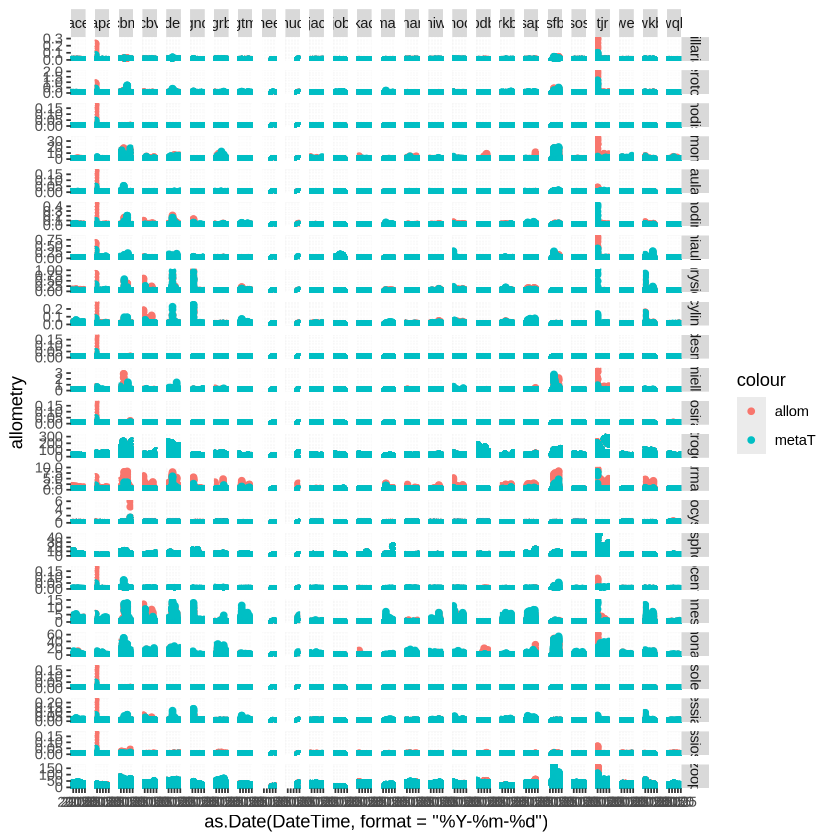

In [17]:
ggplot(nerrs_merged) + geom_point(aes(x=as.Date(DateTime,format="%Y-%m-%d"),
                                      y=allometry,color="allom"))+ 
    geom_point(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color="metaT")) + 
    facet_grid(rows=vars(taxon),cols=vars(Site),scales="free_y")

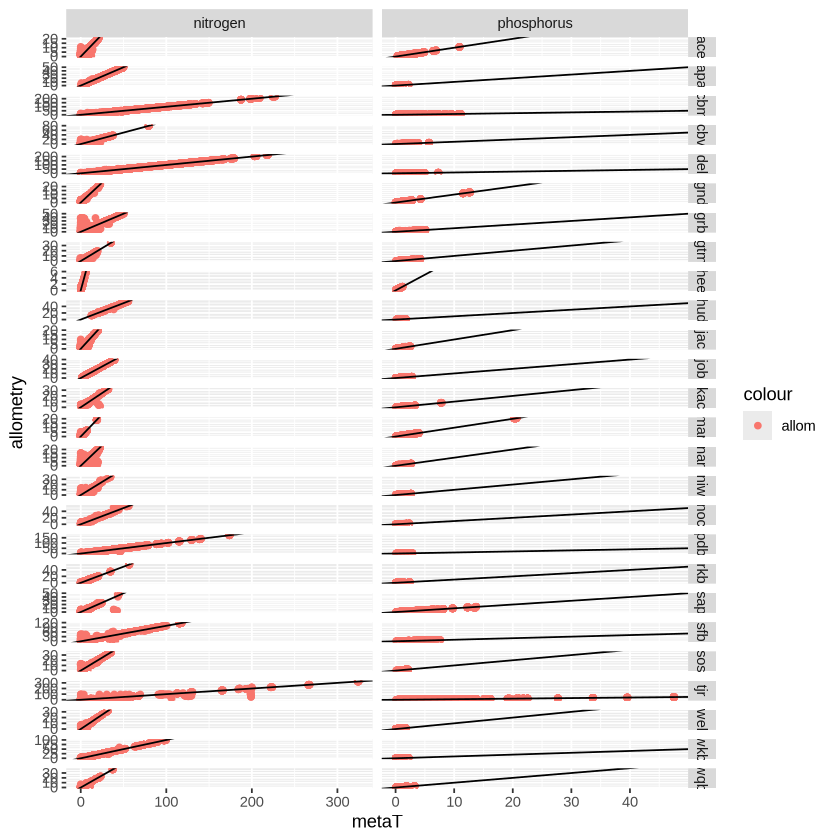

In [18]:
ggplot(nerrs_merged %>% dplyr::filter(taxon%in%c("nitrogen","phosphorus"))) + 
       geom_point(aes(x=metaT,y=allometry,color="allom"))+ 
    facet_grid(cols=vars(taxon),rows=vars(Site),scales="free")+ 
    geom_abline(aes(slope=1,intercept=0))

In [16]:
nerrs_merged

X.x,DateTime,index.x,taxon,metaT,Site,X.y,index.y,allometry
<int>,<chr>,<int>,<chr>,<dbl>,<chr>,<int>,<int>,<dbl>
6,2002-05-23,51,Bacillariales,0.070242279,apa,125,51,0.23068218
13,2002-05-23,51,Cryptomonadales,0.056381117,apa,27,51,0.20556396
20,2002-05-23,51,Phaeocystales,0.047245728,apa,69,51,0.18242290
27,2002-05-23,51,Isochrysidales,0.329812704,apa,13,51,0.83288036
34,2002-05-23,51,Prorocentrales,0.047806137,apa,76,51,0.18367422
41,2002-05-23,51,Prymnesiales,5.453637180,apa,90,51,5.66970126
48,2002-05-23,51,Hemiaulales,0.341789210,apa,104,51,0.62281009
55,2002-05-23,51,Lithodesmiales,0.047245728,apa,118,51,0.18242290
62,2002-05-23,51,Thalassiosirales,0.047245989,apa,55,51,0.18242386


In [24]:
infill_dates = read.csv("../workflows/run_models/model_outputs_5/metaT_informed/ccb/model_output.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund))

infill_dates_allometry = read.csv("../workflows/run_models/model_outputs_5/allometry/ccb/model_output.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund))

merged_results = infill_dates %>% dplyr::rename(c(abund_metaT=abund)) %>%
    dplyr::left_join(infill_dates_allometry %>% dplyr::rename(c("abund_allom"=abund)),
                     by=c("DateTime","taxon")) %>%
    dplyr::filter(as.Date(DateTime,format="%Y-%m-%d")>as.Date("2000-03-01",format="%Y-%m-%d"))

In [25]:
infill_dates %>% dplyr::filter(as.Date(DateTime,format="%Y-%m-%d") > 
                                        as.Date("2023-08-01",format="%Y-%m-%d"))

X,DateTime,index,taxon,abund,Site
<int>,<chr>,<int>,<chr>,<dbl>,<chr>
3,2023-08-02,8583,Prorocentrales,1.099777e-04,ccb
4,2023-08-03,8584,Prorocentrales,1.140549e-04,ccb
5,2023-08-04,8585,Prorocentrales,1.186476e-04,ccb
6,2023-08-05,8586,Prorocentrales,1.232711e-04,ccb
7,2023-08-06,8587,Prorocentrales,1.278239e-04,ccb
8,2023-08-07,8588,Prorocentrales,1.321417e-04,ccb
9,2023-08-08,8589,Prorocentrales,1.363249e-04,ccb
10,2023-08-09,8590,Prorocentrales,1.402915e-04,ccb
11,2023-08-10,8591,Prorocentrales,1.441222e-04,ccb


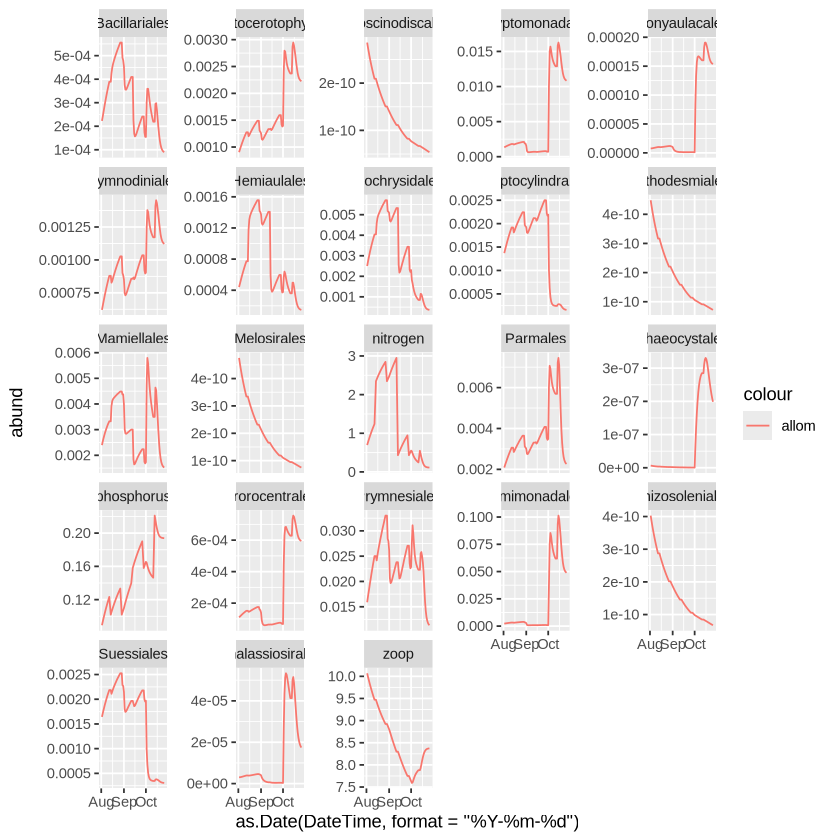

In [22]:
ggplot(infill_dates %>% dplyr::filter(as.Date(DateTime,format="%Y-%m-%d") > 
                                        as.Date("2023-08-01",format="%Y-%m-%d"))) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=abund,color="allom"))+ 
    facet_wrap(~taxon,scales="free_y")

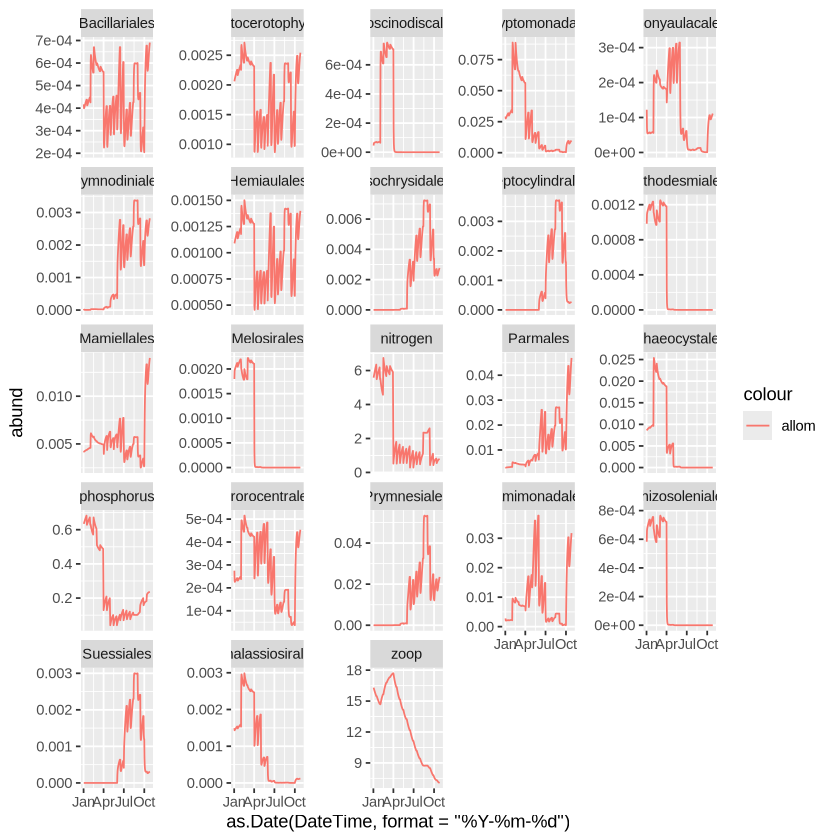

In [23]:
ggplot(infill_dates_allometry %>% dplyr::filter(as.Date(DateTime,format="%Y-%m-%d") > 
                                        as.Date("2023-01-01",format="%Y-%m-%d"))) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=abund,color="allom"))+ 
    facet_wrap(~taxon,scales="free_y")

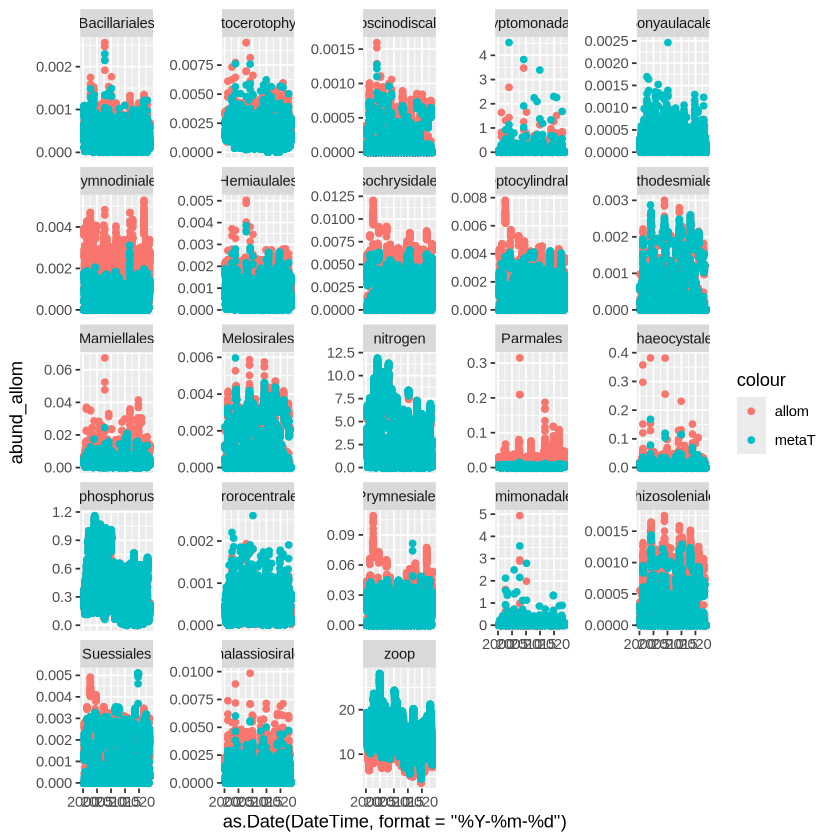

In [24]:
ggplot(merged_results) + geom_point(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=abund_allom,color="allom"))+ 
    geom_point(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=abund_metaT,color="metaT")) + 
    facet_wrap(~taxon,scales="free_y")

Warning message:
“Removed 112240 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 112240 rows containing missing values or values outside the scale range
(`geom_point()`).”


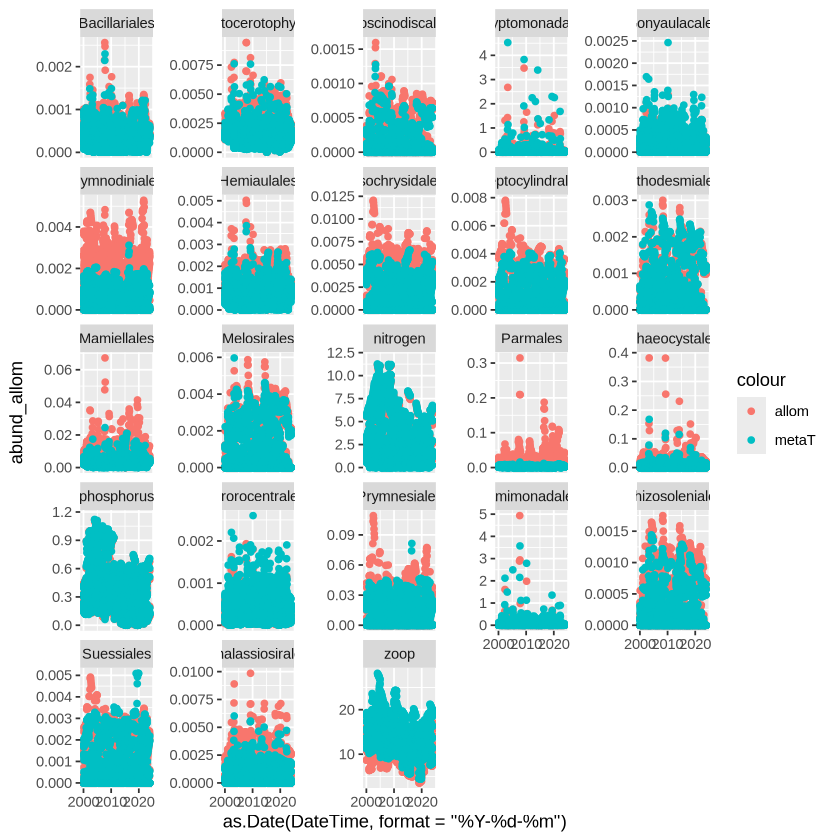

In [25]:
ggplot(merged_results) + geom_point(aes(x=as.Date(DateTime,format="%Y-%d-%m"),y=abund_allom,color="allom"))+ 
    geom_point(aes(x=as.Date(DateTime,format="%Y-%d-%m"),y=abund_metaT,color="metaT")) + 
    facet_wrap(~taxon,scales="free_y")

In [26]:
results_fr=data.frame()
for (taxon_curr in unique(merged_results$taxon)) {
    sub_fr = merged_results %>% dplyr::filter(taxon==taxon_curr)
    corr_curr = cor.test(sub_fr$abund_metaT,sub_fr$abund_allom,method="pearson")
    results_fr = results_fr %>%
        dplyr::bind_rows(data.frame("taxon"=taxon_curr,
                                     corr = corr_curr$estimate,
                                     pval = corr_curr$p.value))
}

In [27]:
bats_output_metaT = read.csv("../workflows/run_models/model_outputs_5/metaT_informed/bats_hot/model_output.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund))

bats_output_allometry = read.csv("../workflows/run_models/model_outputs_5/allometry/bats_hot/model_output.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund))

bats_results = bats_output_metaT %>% dplyr::rename(c(abund_metaT=abund)) %>%
    dplyr::left_join(bats_output_allometry %>% dplyr::rename(c("abund_allom"=abund)),
                     by=c("DateTime","taxon","Site")) %>%
    dplyr::filter(as.Date(DateTime,format="%Y-%m-%d")>as.Date("2000-03-01",format="%Y-%m-%d"))

In [28]:
bats_data_p <- read.csv("../data/bats/BATS_Bottle_ll_phosphorus_data.csv") %>%
  mutate(DateTime = lubridate::ymd_hms(time),
         phosphorus = low_level_phosphorus / 1000 * 1.025, # original units nmol/kg -> uM
         site = "BATS")

bats_data_n <- read.csv("../data/bats/BATS_Bottle_no3_no2_data.csv") %>%
  mutate(DateTime = lubridate::ymd_hms(time),
         nitrogen = nitrate_nitrite * 1.025, # original units umol/kg -> uM
         site = "BATS")

bats_data_temp <- read.csv("../data/bats/BATS_Bottle_temp_data.csv") %>%
  mutate(DateTime = ymd_hms(time),
         site = "BATS")

hot_data_p <- read.csv("../data/hot/HOT_Bottle_ALOHA_ll_phosphorus_data.csv") %>%
  mutate(DateTime = lubridate::ymd_hms(time),
    phosphorus = llp / 1000 * 1.025, #  nmol/kg -> uM
    site = "HOT")

hot_data_n <- read.csv("../data/hot/HOT_Bottle_ALOHA_ll_nitrogen_data.csv") %>%
  mutate(DateTime = lubridate::ymd_hms(time),
    nitrogen = lln / 1000 * 1.025, # nmol/kg -> uM
    site = "HOT")

hot_data_temp <- read.csv("../data/hot/HOT_Bottle_ALOHA_temp_data.csv") %>%
  mutate(DateTime = lubridate::ymd_hms(time),
         site = "HOT")

temp_data_all <- bind_rows(hot_data_temp, bats_data_temp)

bats_nutrients <- inner_join(bats_data_p, bats_data_n)
hot_nutrients <- inner_join(hot_data_p, hot_data_n)

nutrient_data_all_bats_hot <- bind_rows(bats_nutrients, hot_nutrients) %>%
  filter(depth < 5) %>%
  group_by(DateTime, site) %>%
  summarise(
    phosphorus = mean(phosphorus, na.rm = TRUE),
    nitrogen = mean(nitrogen, na.rm = TRUE),
    .groups = "drop"
  )

Joining with `by = join_by(time, lat, lon, depth, DateTime, site)`
Joining with `by = join_by(time, lat, lon, depth, DateTime, site)`
Warning message in inner_join(hot_data_p, hot_data_n):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 889 of `x` matches multiple rows in `y`.
ℹ Row 3433 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


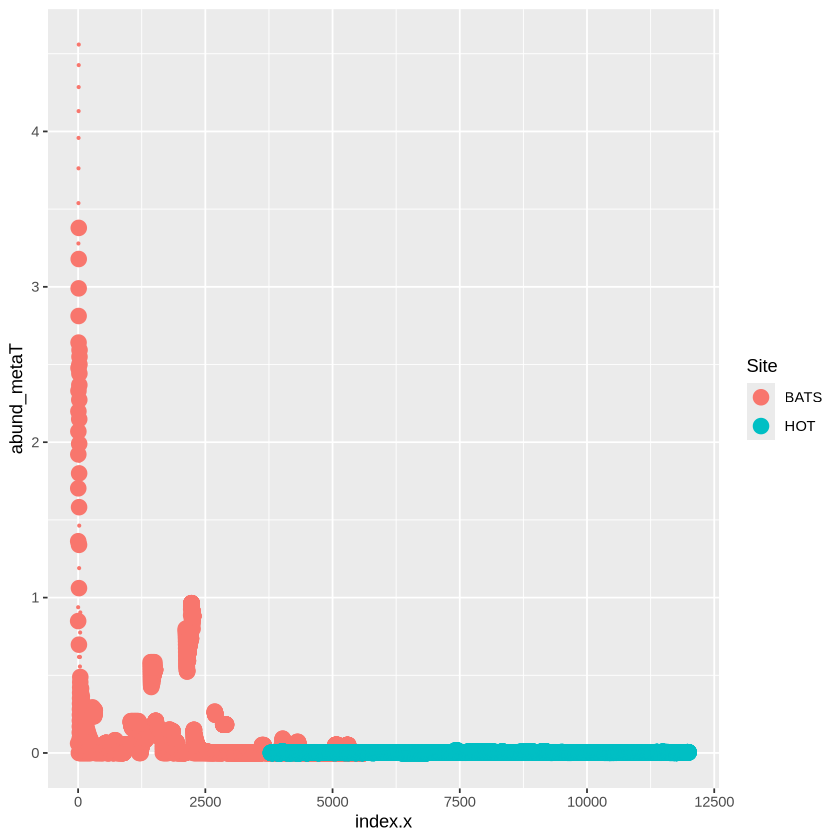

In [121]:
ggplot(bats_results %>% dplyr::filter(taxon=="nitrogen")) + #as.Date(DateTime,format="%Y-%m-d")
    geom_point(aes(x=index.x,y=abund_metaT,color=Site),size=0.5)+
    geom_point(aes(x=index.x,y=abund_allom,color=Site),size=4)

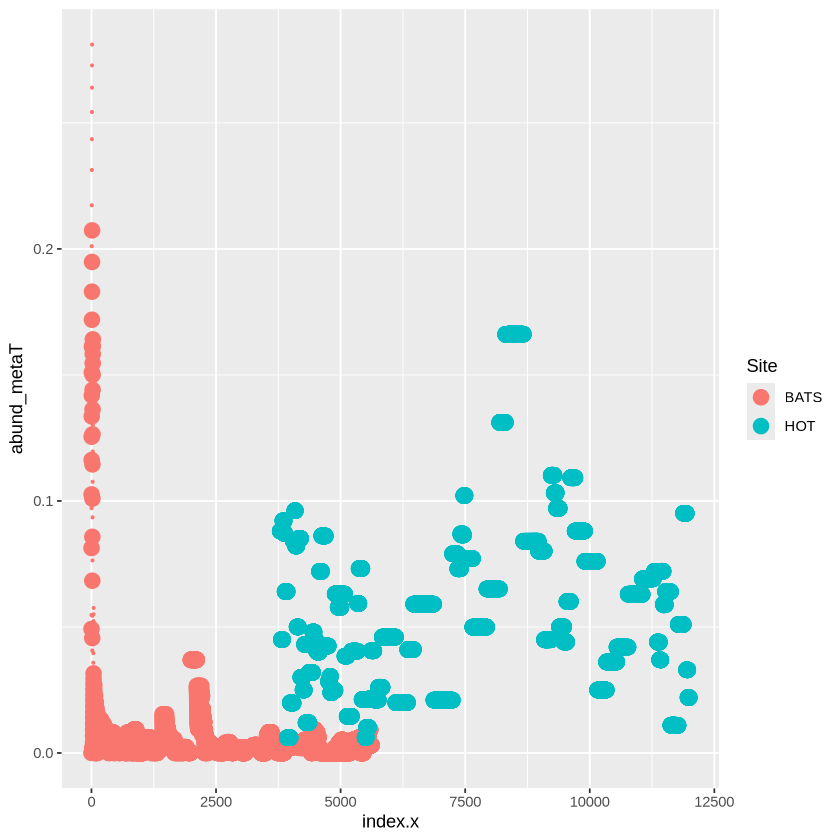

In [38]:
ggplot(bats_results %>% dplyr::filter(taxon=="phosphorus")) + #as.Date(DateTime,format="%Y-%m-d")
    geom_point(aes(x=index.x,y=abund_metaT,color=Site),size=0.5)+
    geom_point(aes(x=index.x,y=abund_allom,color=Site),size=4)

In [29]:
results_fr_bats=data.frame()
for (taxon_curr in unique(bats_results$taxon)) {
    for (site_curr in unique(bats_results$Site)) {
        sub_fr = bats_results %>% dplyr::filter(taxon==taxon_curr) %>%
            dplyr::filter(Site==site_curr)
        corr_curr = cor.test(sub_fr$abund_metaT,sub_fr$abund_allom,method="pearson")
        results_fr_bats = results_fr_bats %>%
            dplyr::bind_rows(data.frame("taxon"=taxon_curr,
                                        "site"=site_curr,
                                         corr = corr_curr$estimate,
                                         pval = corr_curr$p.value))
    }
}

Warning message in cor(x, y):
“the standard deviation is zero”


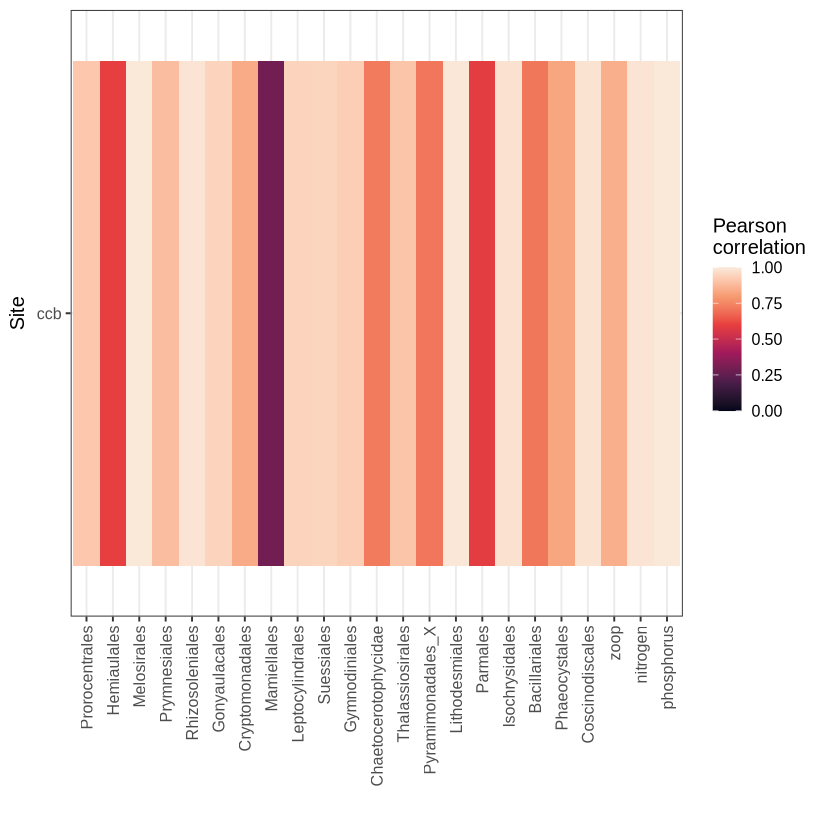

In [30]:
ggplot(results_fr %>% dplyr::mutate(site="ccb"))+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

In [34]:
results_fr_bats

,taxon,site,corr,pval
,<chr>,<chr>,<dbl>,<dbl>
cor...1,Rhizosoleniales,BATS,0.9729386,0
cor...2,Rhizosoleniales,HOT,0.9917949,0
cor...3,Mamiellales,BATS,0.9129204,0
cor...4,Mamiellales,HOT,0.7095121,0
cor...5,Cryptomonadales,BATS,0.9728366,0
cor...6,Cryptomonadales,HOT,0.8868251,0
cor...7,Phaeocystales,BATS,0.9729333,0
cor...8,Phaeocystales,HOT,0.9955554,0
cor...9,Prorocentrales,BATS,0.9729361,0


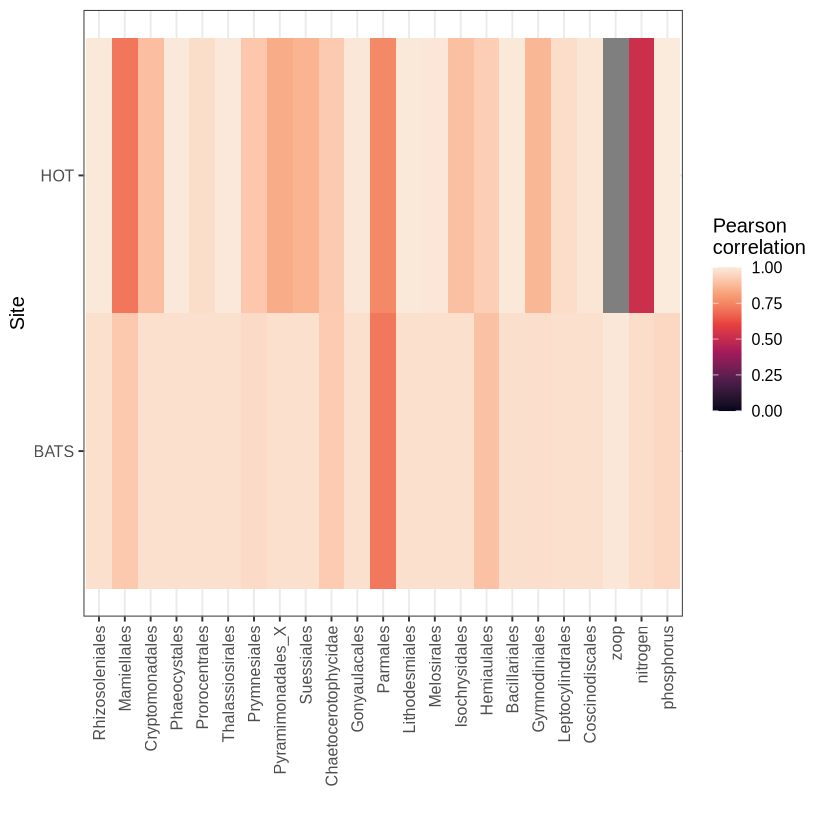

In [35]:
ggplot(results_fr_bats)+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

In [41]:
corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(taxon) %>%
    dplyr::summarize(mean_corr=mean(corr), std_corr=sd(corr),
                     min_corr = min(corr)) %>%
    dplyr::arrange(mean_corr)

taxon,mean_corr,std_corr,min_corr
<chr>,<dbl>,<dbl>,<dbl>
Mamiellales,0.6063789,0.25716526,7.037017e-03
Cryptomonadales,0.6593208,0.27504849,8.854871e-02
Parmales,0.6947827,0.25360311,-6.458048e-06
Pyramimonadales_X,0.6956400,0.26103224,7.768476e-02
Hemiaulales,0.7040559,0.23108453,-3.004766e-03
Chaetocerotophycidae,0.7517740,0.22974032,-1.119208e-03
Prymnesiales,0.8081872,0.24079411,1.664823e-02
Thalassiosirales,0.8517585,0.22863614,1.444545e-01
Bacillariales,0.8529323,0.18648946,2.355144e-02


In [32]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)

summarize_corr_site = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(site) %>% dplyr::summarize(avg_corr = mean(corr)) %>%
    dplyr::arrange(avg_corr)

summarize_corr_taxon = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(taxon) %>% dplyr::summarize(avg_corr = mean(corr)) %>%
    dplyr::arrange(avg_corr)

check_res = for_tile %>% dplyr::bind_rows(results_fr%>% 
                                                   dplyr::mutate(site="ccb")) %>% 
                     dplyr::bind_rows(results_fr_bats) %>% 
                     dplyr::filter(taxon%in%unique(summarize_corr_taxon$taxon))
                     
check_res %>% 
    dplyr::group_by(site) %>%
    dplyr::summarize(mean_corr=mean(corr), std_corr=sd(corr), n_points = n()) %>%
    dplyr::arrange(mean_corr)

site,mean_corr,std_corr,n_points
<chr>,<dbl>,<dbl>,<int>
tjr,0.3381980,0.38062027,20
hee,0.7296340,0.28296972,20
grb,0.7678991,0.26768684,20
cbv,0.7757750,0.19214405,20
pdb,0.7815608,0.31937191,20
sap,0.7869715,0.22790915,20
mar,0.7919417,0.17424567,20
wqb,0.7922038,0.18668775,20
kac,0.8274883,0.27079432,20


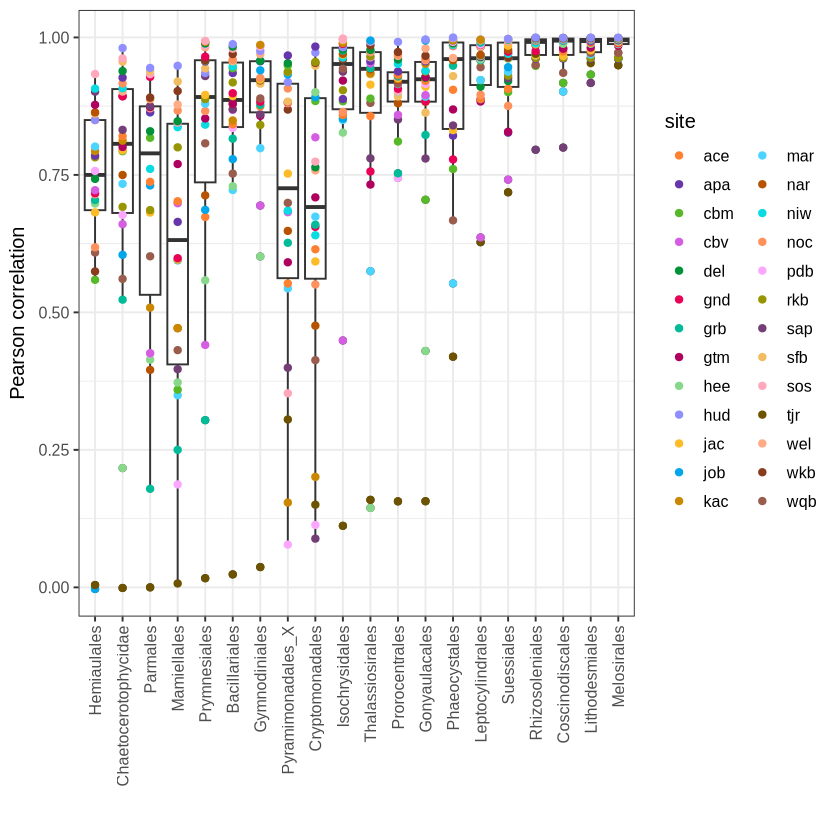

In [17]:
ggplot(corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr))+ 
    geom_boxplot(aes(x=factor(taxon,levels=unique(taxon)),group=taxon,y=corr))+ 
    geom_point(aes(x=factor(taxon,levels=unique(taxon)),color=site,group=site,y=corr))+ 
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Pearson correlation") + xlab("") + 
    scale_color_manual(values=c("#ff8030",
"#6836ab",
"#57b928",
"#d45de2",
"#009238",
"#e90057",
"#01bb99",
"#b0005f",
"#88d88c",
"#908fff",
"#fcbb27",
"#02a6eb",
"#c98800",
"#4ad4ff",
"#b75300",
"#08dbe2",
"#ff925c",
"#fca7ff",
"#979500",
"#733f76",
"#f2bd61",
"#ffa7bb",
"#6d5200",
"#ffab85",
"#883c1d",
"#9a5d4d"))

Saving 6.67 x 6.67 in image


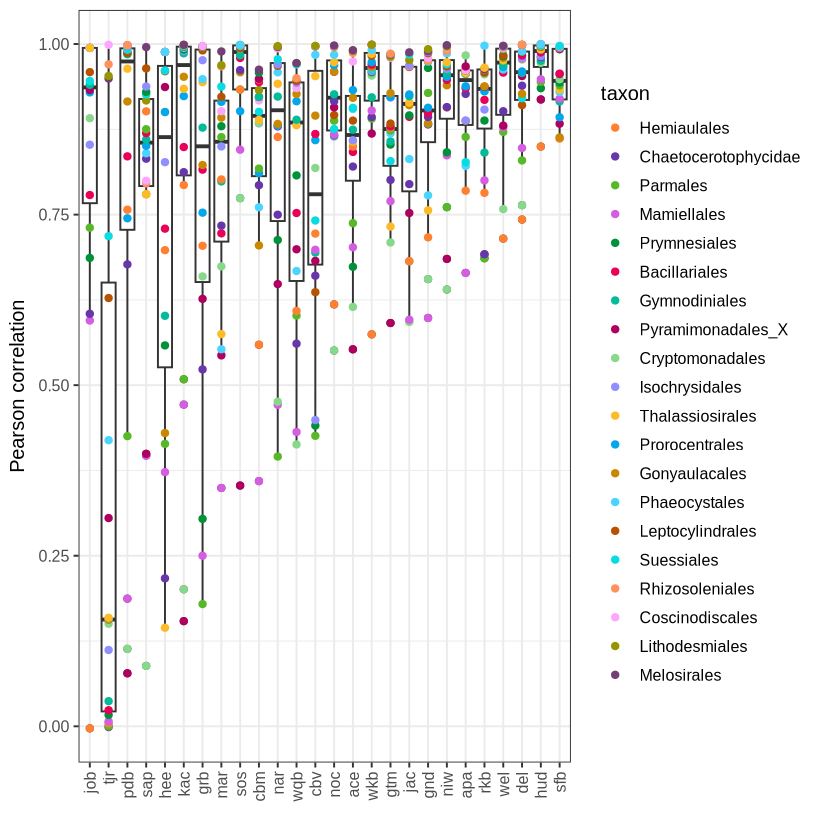

In [18]:
ggplot(corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr))+ 
    geom_boxplot(aes(x=factor(site,levels=unique(site)),y=corr))+ 
    geom_point(aes(color=factor(taxon,levels=unique(taxon)),
                   x=factor(site,levels=unique(site)),group=site,y=corr))+ 
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Pearson correlation") + xlab("") + 
    scale_color_manual(values=c("#ff8030",
"#6836ab",
"#57b928",
"#d45de2",
"#009238",
"#e90057",
"#01bb99",
"#b0005f",
"#88d88c",
"#908fff",
"#fcbb27",
"#02a6eb",
"#c98800",
"#4ad4ff",
"#b75300",
"#08dbe2",
"#ff925c",
"#fca7ff",
"#979500",
"#733f76",
"#f2bd61",
"#ffa7bb",
"#6d5200",
"#ffab85",
"#883c1d",
"#9a5d4d"),name="taxon")

ggsave("../figures/compare_taxa_nerrs.pdf")

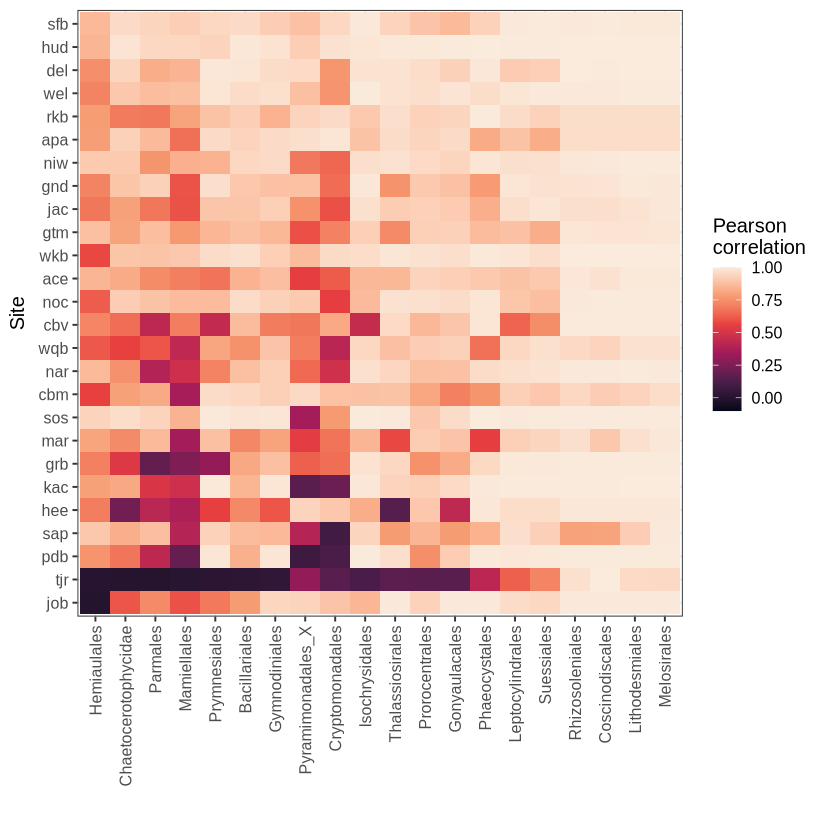

In [39]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)
ggplot(for_tile)+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(-0.1, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

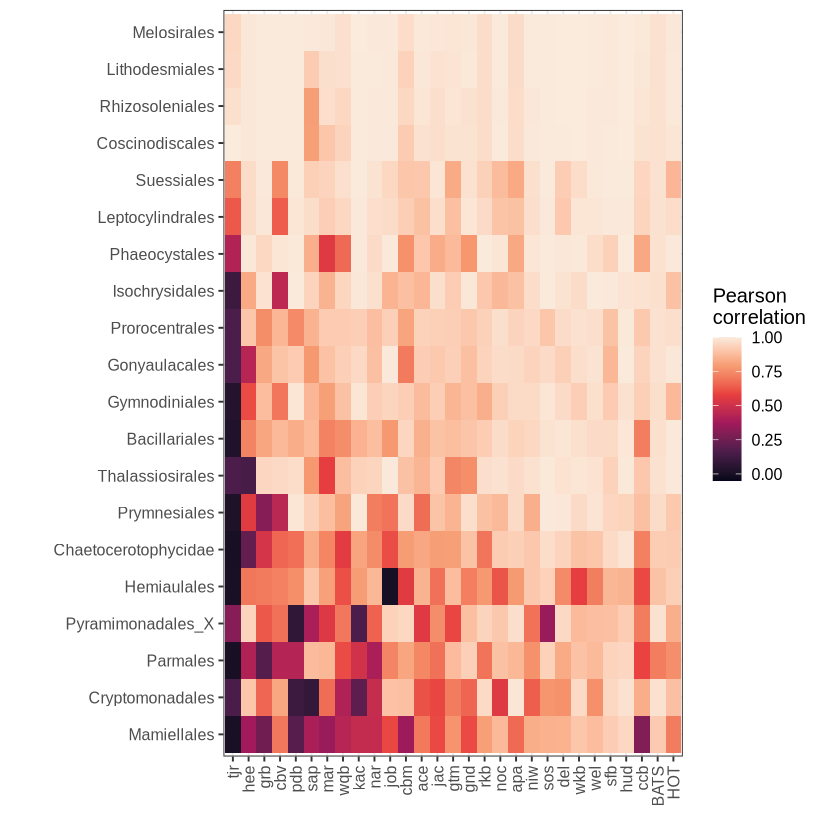

In [41]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)

summarize_corr_site = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(site) %>% dplyr::summarize(avg_corr = mean(corr)) %>%
    dplyr::arrange(avg_corr)

summarize_corr_taxon = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(taxon) %>% dplyr::summarize(avg_corr = mean(corr)) %>%
    dplyr::arrange(avg_corr)

rotate_tile = ggplot(for_tile %>% dplyr::bind_rows(results_fr%>% 
                                                   dplyr::mutate(site="ccb")) %>% 
                     dplyr::bind_rows(results_fr_bats) %>% 
                     dplyr::filter(taxon%in%unique(summarize_corr_taxon$taxon)))+ 
    geom_tile(aes(y=factor(taxon,levels=unique(summarize_corr_taxon$taxon)),
                  x=factor(site,levels=c(unique(summarize_corr_site$site),"ccb","BATS","HOT")),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(-0.05, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("") + xlab("")

rotate_tile

In [156]:
summarize_corr_site %>% arrange(avg_corr)

site,avg_corr
<chr>,<dbl>
tjr,0.1993554
gtm,0.5999054
hud,0.6267282
del,0.6280356
mar,0.6434707
pdb,0.6469469
kac,0.6681678
sap,0.6689484
sfb,0.6726430


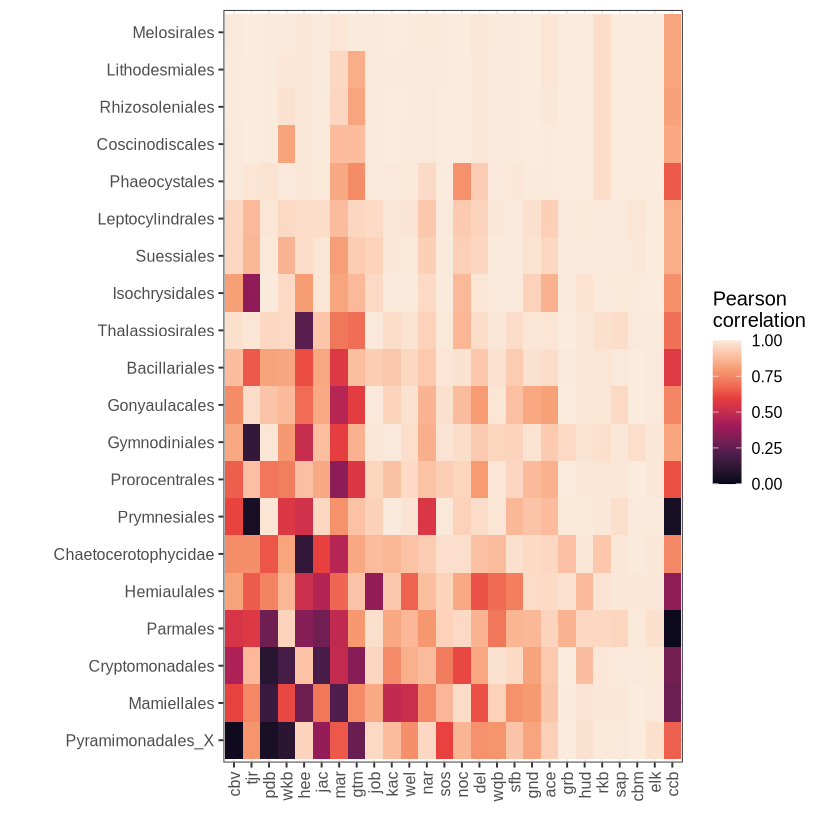

In [40]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)

summarize_corr_site = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(site) %>% dplyr::summarize(avg_corr = min(corr)) %>%
    dplyr::arrange(avg_corr)

summarize_corr_taxon = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(taxon) %>% dplyr::summarize(avg_corr = mean(corr)) %>%
    dplyr::arrange(avg_corr)

rotate_tile = ggplot(for_tile %>% dplyr::bind_rows(results_fr%>% 
                                                   dplyr::mutate(site="ccb")) %>% 
                     dplyr::filter(taxon%in%unique(summarize_corr_taxon$taxon)))+ 
    geom_tile(aes(y=factor(taxon,levels=unique(summarize_corr_taxon$taxon)),
                  x=factor(site,levels=c(unique(summarize_corr_site$site),"ccb")),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("") + xlab("")

rotate_tile

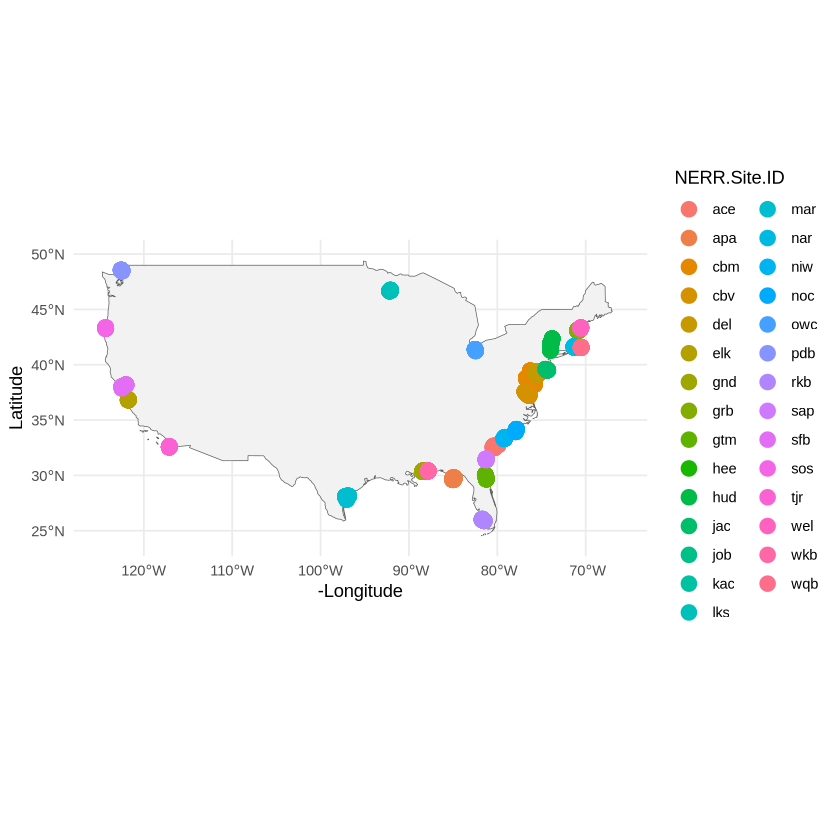

In [133]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

ggplot() +
  geom_sf(data = usa, fill = "gray95") +
  geom_point(data = nerrs_metadata, aes(x = -Longitude, y = Latitude,col=NERR.Site.ID), size = 4) +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50)) + # Zoom into mainland USA
  theme_minimal()

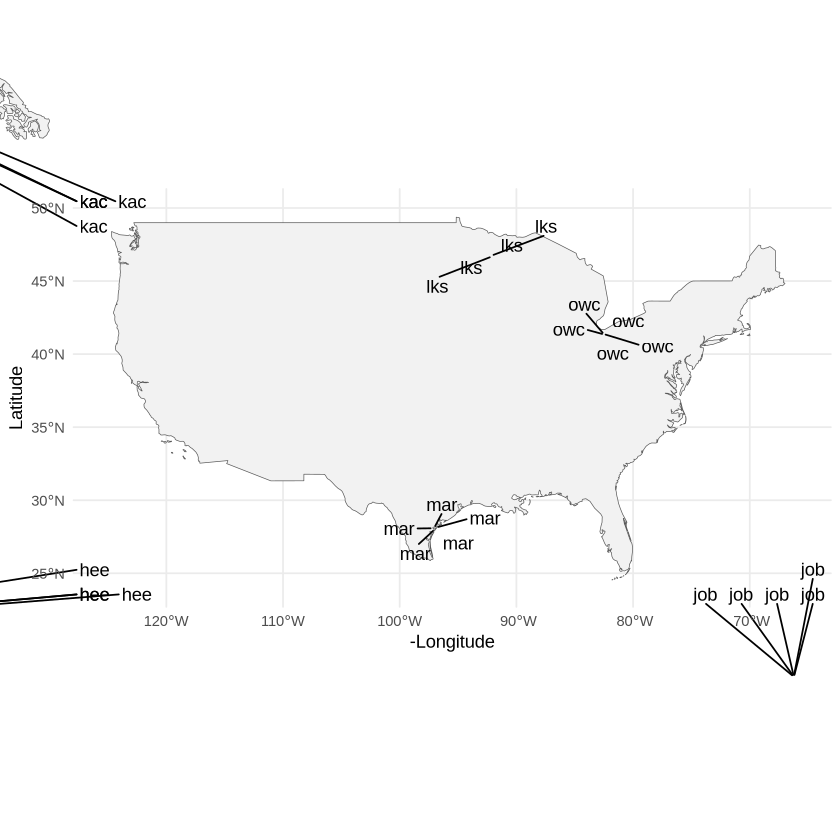

In [42]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

ggplot() +
  geom_sf(data = usa, fill = "gray95") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::mutate(Latitude=round(Latitude,2),
                          Longitude=round(Longitude,2)) %>%
            dplyr::distinct(Latitude,Longitude,NERR.Site.ID), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID)) +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50),clip = "off") + # Zoom into mainland USA
  theme_minimal()

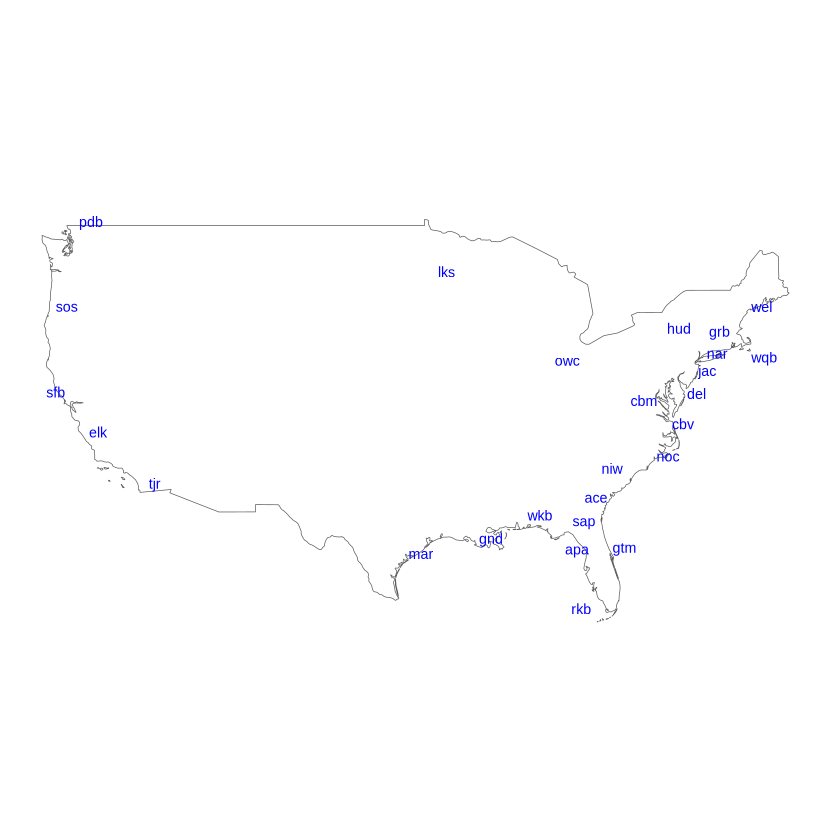

In [53]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

map_plt = ggplot() +
  geom_sf(data = usa, fill = "white") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::filter(!(NERR.Site.ID%in%c("kac","job","hee"))) %>%
            dplyr::group_by(NERR.Site.ID)%>%
            dplyr::summarize(Latitude=mean(Latitude),
                             Longitude=mean(Longitude)), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID),
    max.overlaps = Inf,size=3,color="blue") +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50),clip = "off") + # Zoom into mainland USA
  theme_void() + xlab("") + ylab("")
map_plt

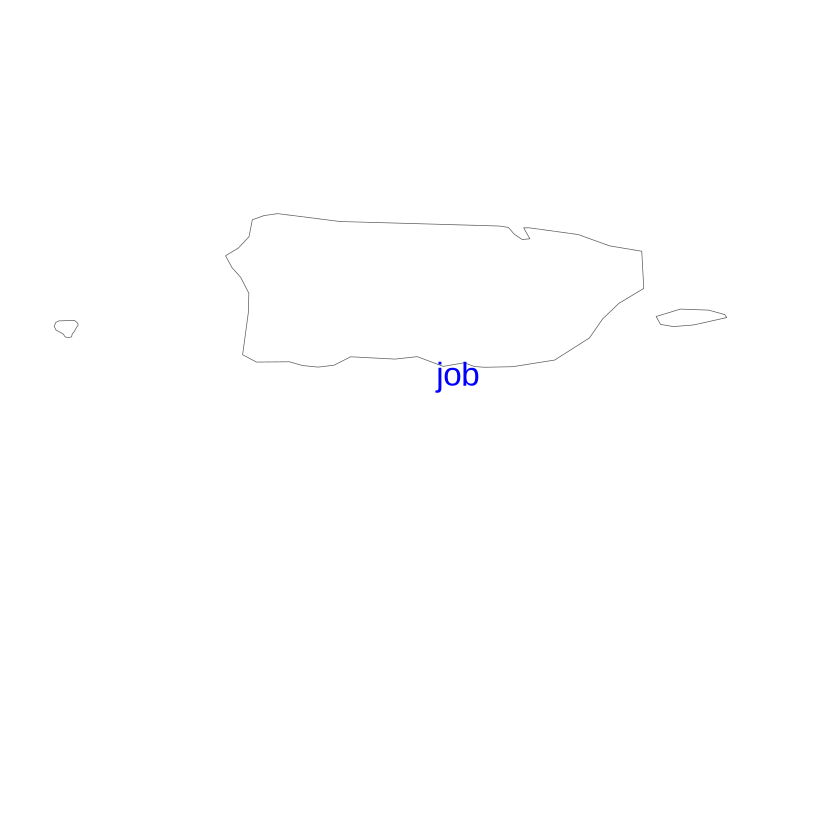

In [44]:
caribbean_map <- ne_countries(scale = "medium", type = "map_units", returnclass = "sf")

# Filter specifically for Puerto Rico
puerto_rico <- caribbean_map[caribbean_map$name == "Puerto Rico", ]

pr_map = ggplot() +
  geom_sf(data = puerto_rico, fill = "white") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::group_by(NERR.Site.ID)%>%
            dplyr::summarize(Latitude=mean(Latitude),
                             Longitude=mean(Longitude)) %>% dplyr::filter(NERR.Site.ID=="job"), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID),color="blue",size = 7,
    max.overlaps = Inf) +
  coord_sf(xlim = c(-68, -65), ylim = c(17.5,18),clip = "off") + # Zoom into mainland USA
  theme_void() + xlab("") + ylab("")
pr_map

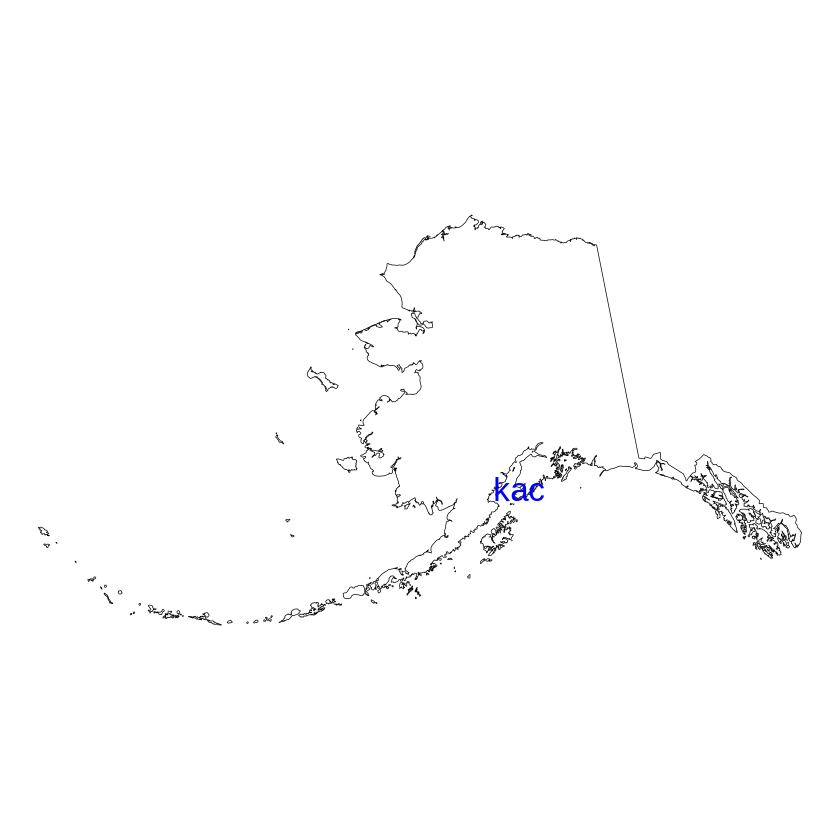

In [48]:
# 1. Fetch US state boundaries from Natural Earth
us_states <- ne_states(country = "United States of America", returnclass = "sf")

# 2. Filter specifically for Alaska
alaska <- us_states[us_states$name == "Alaska", ]

# 3. Reproject to Alaska Albers (EPSG:3338) to fix 180th meridian wrapping
alaska_3338 <- st_transform(alaska, crs = 3338)

# 1. Aggregate and filter your NERRS data using standard degrees
kac_data_deg <- nerrs_metadata %>%
  dplyr::group_by(NERR.Site.ID) %>%
  dplyr::summarize(
    Latitude = mean(Latitude),
    # If your raw Longitude is positive (151.1), make it negative here:
    Longitude = ifelse(mean(Longitude) > 0, -mean(Longitude), mean(Longitude))
  ) %>% 
  dplyr::filter(NERR.Site.ID == "kac")

# 2. Convert the data frame into a spatial sf object (WGS84 degrees / EPSG:4326)
kac_sf_deg <- st_as_sf(kac_data_deg, coords = c("Longitude", "Latitude"), crs = 4326)

# 3. Transform the point to match the Alaska Albers projection (meters / EPSG:3338)
kac_sf_3338 <- st_transform(kac_sf_deg, crs = 3338)

ak_map = ggplot() +
  geom_sf(data = alaska_3338, color="black", fill = "white") +
  geom_sf_text(data = kac_sf_3338, aes(label = NERR.Site.ID), color="blue",size = 7, 
               fun.geometry = sf::st_geometry) +
  #coord_sf(xlim = c(-160,-150), ylim = c(59,61),clip = "off") + # Zoom into mainland USA
  theme_void() + xlab("") + ylab("")
ak_map

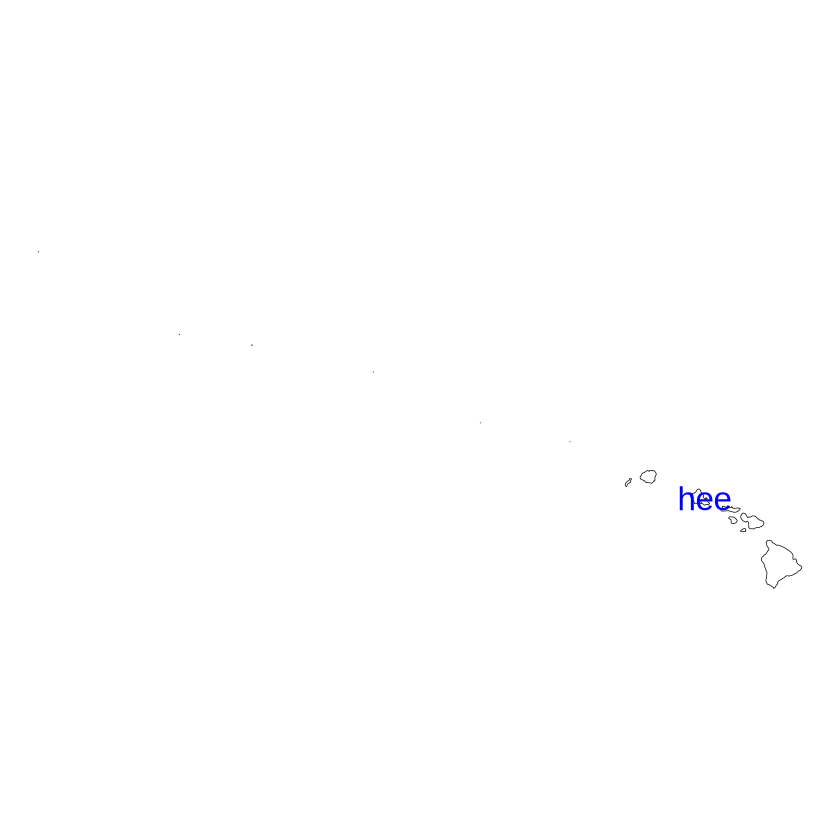

In [47]:
# 1. Fetch US state boundaries from Natural Earth
us_states <- ne_states(country = "United States of America", returnclass = "sf")

# 2. Filter specifically for Alaska
hawaii <- us_states[us_states$name == "Hawaii", ]

# 1. Aggregate and filter your NERRS data using standard degrees
hee_data_deg <- nerrs_metadata %>%
  dplyr::group_by(NERR.Site.ID) %>%
  dplyr::summarize(
    Latitude = mean(Latitude),
    # If your raw Longitude is positive (151.1), make it negative here:
    Longitude = ifelse(mean(Longitude) > 0, -mean(Longitude), mean(Longitude))
  ) %>% 
  dplyr::filter(NERR.Site.ID == "hee")

# 2. Convert the data frame into a spatial sf object (WGS84 degrees / EPSG:4326)
hi_df <- st_as_sf(hee_data_deg, coords = c("Longitude", "Latitude"), crs = 4326)

hi_map = ggplot() +
  geom_sf(data = hawaii, color="black", fill = "white") +
  geom_sf_text(data = hi_df, aes(label = NERR.Site.ID), color="blue",size = 7, 
               fun.geometry = sf::st_geometry) +
  #coord_sf(xlim = c(-160,-150), ylim = c(59,61),clip = "off") + # Zoom into mainland USA
  theme_void() + xlab("") + ylab("")
hi_map

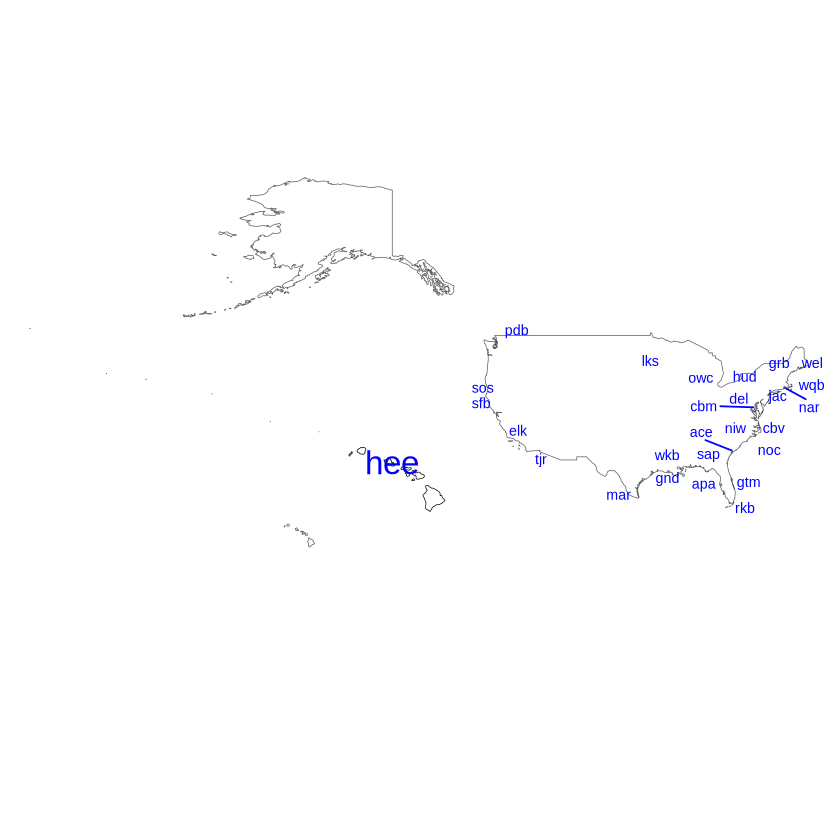

In [54]:
hi_map|map_plt

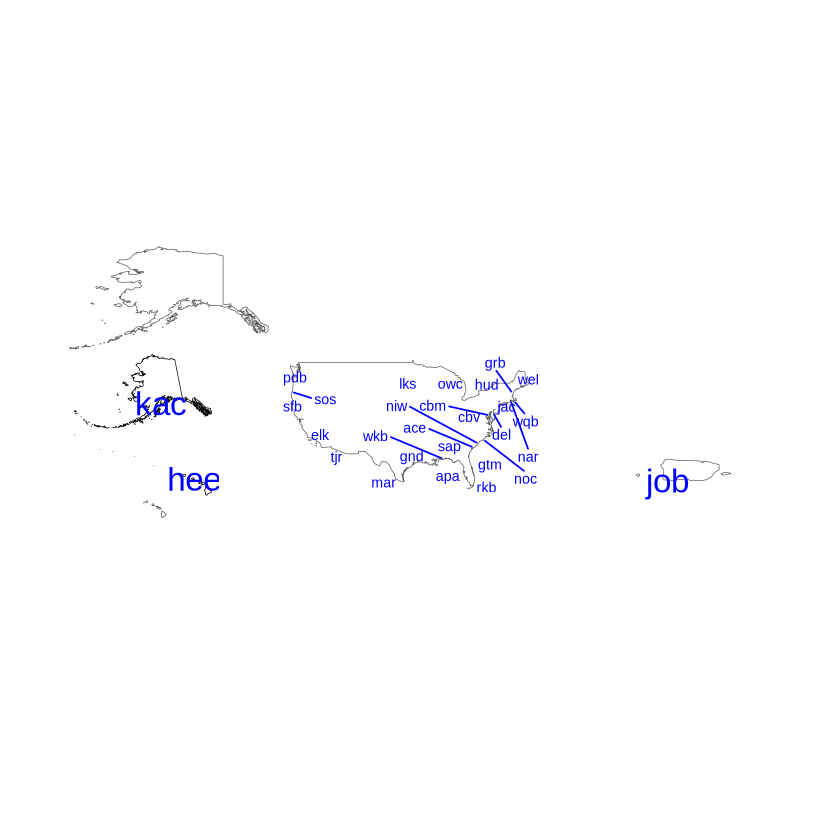

In [55]:
(ak_map/hi_map) | map_plt | (plot_spacer()/pr_map)

In [57]:
## read in environmental phosphate abundances
phos_ptown = read.csv("../data/phosphorus.csv")
phos_ptown = read.csv("../data/nutrients/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/nutrients/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))

phos_ptown_dt = phos_ptown%>% dplyr::filter(PARAM_CODE=="PO4") %>% 
    dplyr::filter(DEPTH<5)
phos_ptown_dt = phos_ptown_dt %>% dplyr::group_by(Date,STAT_ID) %>%
    dplyr::summarize(phosphorus = mean(FFU_RESULT))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

## read in environmental nitrate/nitrite/ammonium abundances
nitr_ptown = read.csv("../data/nitrogen.csv")
nitr_ptown = read.csv("../data/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
nitr_ptown_dt = nitr_ptown%>% dplyr::filter(DEPTH<5)

nitr_ptown_dt = nitr_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NO2","NO3","NO3+NO2")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

nitr_ptown_dt = nitr_ptown_dt %>% 
    dplyr::rename(c("NO3_NO2"="NO3+NO2")) %>%
    dplyr::mutate(nitrate = case_when(is.na(NO3_NO2) ~ NO3+NO2,
                                      TRUE~NO3_NO2))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

ammon_ptown = read.csv("../data/nitrogen.csv")
ammon_ptown = read.csv("../data/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
ammon_ptown_dt = ammon_ptown %>% dplyr::filter(DEPTH<5)

ammon_ptown_dt = ammon_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NH4")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

ammon_ptown_dt = ammon_ptown_dt %>% 
    dplyr::rename(c("ammonium"="NH4")) %>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date and STAT_ID.
ℹ Output is grouped by Date.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, STAT_ID))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by PARAM_CODE, STAT_ARRIV, STAT_ID, and Date.
ℹ Output is grouped by PARAM_CODE, STAT_ARRIV, and STAT_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(PARAM_CODE, STAT_ARRIV, STAT_ID, Date))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by PARAM_CODE, STAT_ARRIV, STAT_ID, and Date.
ℹ Output is grouped by PARAM_CODE, STAT_ARRIV, and STAT_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(PARAM_CODE, STAT_ARRIV, STAT_ID, Date))` for
  per-operation groupi

In [58]:
n_frame = ammon_ptown_dt %>% dplyr::left_join(nitr_ptown_dt) %>%
        dplyr::filter(!is.na(ammonium)&!is.na(nitrate)) %>%
        dplyr::mutate(nitrogen = ammonium + nitrate)

all_nutrients = n_frame %>% dplyr::select(STAT_ARRIV,STAT_ID,SampleDate,nitrogen)%>% 
    dplyr::left_join(phos_ptown_dt) %>% dplyr::mutate(NERR.Site.ID="ccb")

Joining with `by = join_by(STAT_ARRIV, STAT_ID, Date, SampleDate)`
Joining with `by = join_by(STAT_ID, SampleDate)`
Warning message in dplyr::left_join(., phos_ptown_dt):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 4 of `x` matches multiple rows in `y`.
ℹ Row 453 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


Warning message:
“Removed 54 rows containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 54 rows containing missing values or values outside the scale range
(`geom_point()`).”


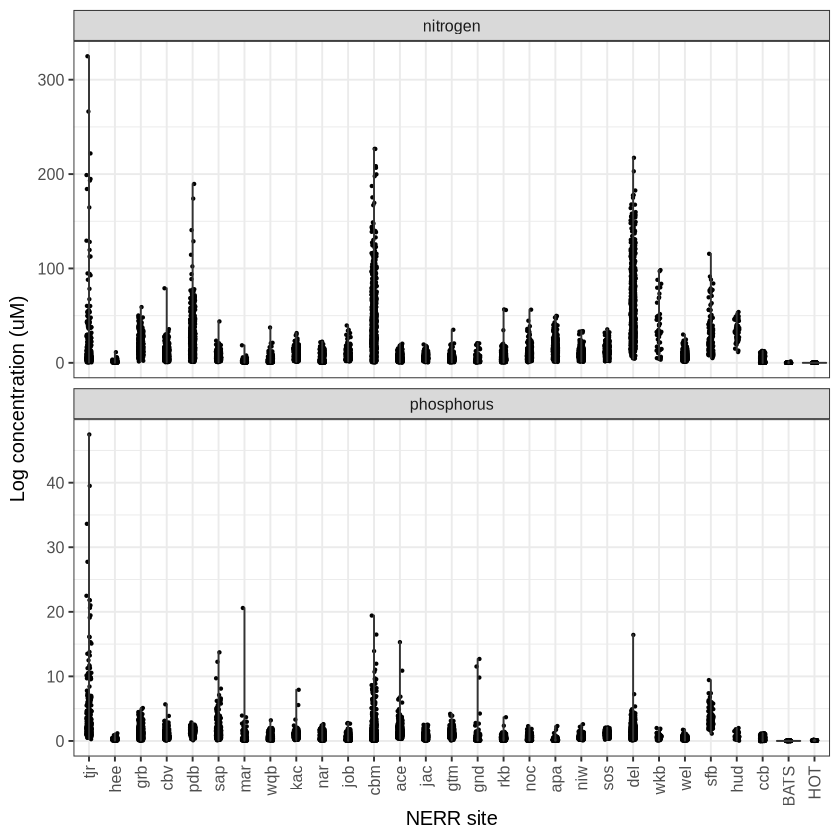

In [59]:
nutrient_box = ggplot(nerrs_nutrients %>%
       dplyr::bind_rows(all_nutrients) %>%
       dplyr::bind_rows(nutrient_data_all_bats_hot %>% dplyr::mutate(NERR.Site.ID=site) %>%
                        dplyr::mutate(DateTime=as.character(DateTime))) %>%
       dplyr::filter(NERR.Site.ID %in% unique(c(for_tile$site,"ccb","BATS","HOT"))) %>%
       dplyr::mutate(DateT=as.Date(DateTime,format="%Y-%m-%d")) %>%
       tidyr::pivot_longer(cols = starts_with("nitrogen")|starts_with("phosphorus"),
                           names_to = "species",
                           values_to = "uM")) + 
       geom_jitter(aes(x=factor(NERR.Site.ID,levels=c(unique(summarize_corr_site$site),
                                                      "ccb","BATS","HOT")),y=uM),
                   height=0,width=0.1,size=0.5) +
       geom_violin(aes(x=factor(NERR.Site.ID,levels=c(unique(summarize_corr_site$site),
                                                      "ccb","BATS","HOT")),y=uM),
                   alpha=0.75,fill="white") +
    facet_wrap(~species,nrow=2,scales="free_y")+
    #scale_y_log10()+ 
    theme_bw(base_size=12) + xlab("NERR site")+
    ylab("Log concentration (uM)") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))
nutrient_box

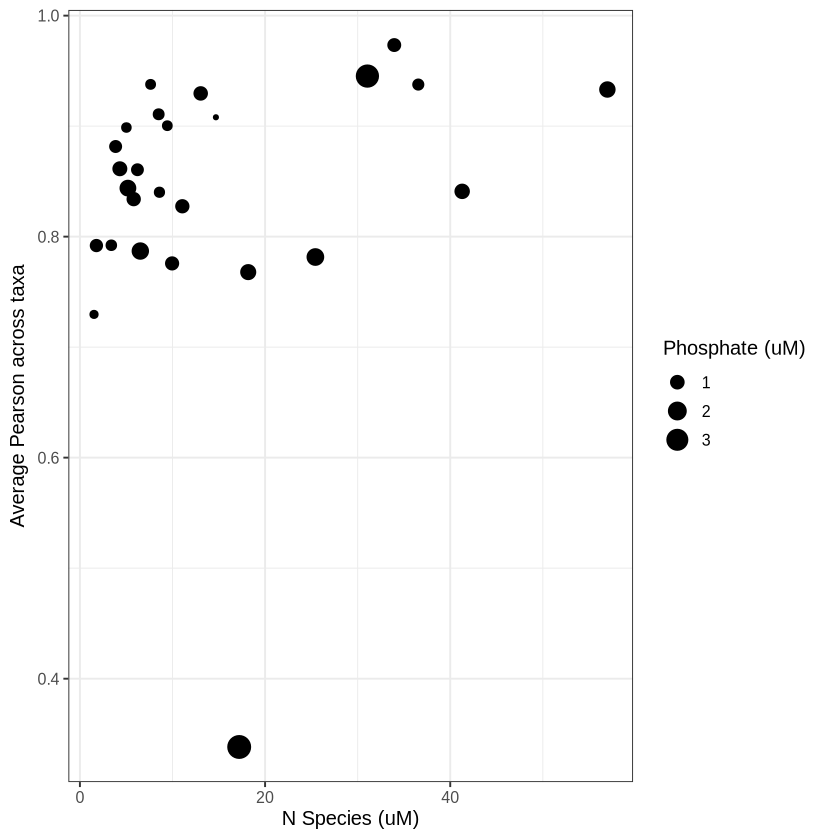

In [60]:
ggplot(nerrs_nutrients %>%
       dplyr::filter(NERR.Site.ID %in% unique(for_tile$site)) %>%
       dplyr::mutate(DateT=as.Date(DateTime,format="%Y-%m-%d")) %>%
    dplyr::group_by(NERR.Site.ID) %>%
    dplyr::summarize(nitrogen=mean(nitrogen),phosphorus=mean(phosphorus)) %>%
    dplyr::left_join(summarize_corr_site,by=c("NERR.Site.ID"="site"))) + 
    geom_point(aes(x=nitrogen,y=avg_corr,size=phosphorus)) + 
    theme_bw(base_size=12) + 
    ylab("Average Pearson across taxa") + xlab("N Species (uM)") + 
    scale_size(name="Phosphate (uM)")

Warning message:
“Removed 54 rows containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 54 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 54 rows containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 54 rows containing missing values or values outside the scale range
(`geom_point()`).”


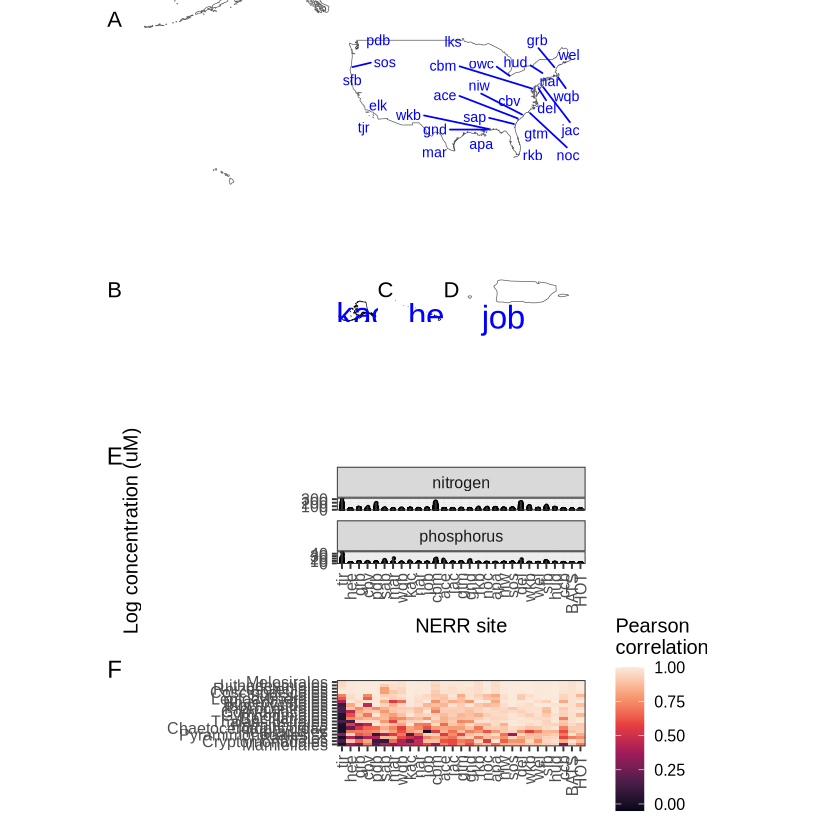

In [72]:
((map_plt / (ak_map|hi_map|pr_map))/(nutrient_box/rotate_tile))+plot_annotation(tag_levels = "A") 
ggsave("../figures/figure_4_nutrients_rev.pdf",width=10,height=18,units="in")

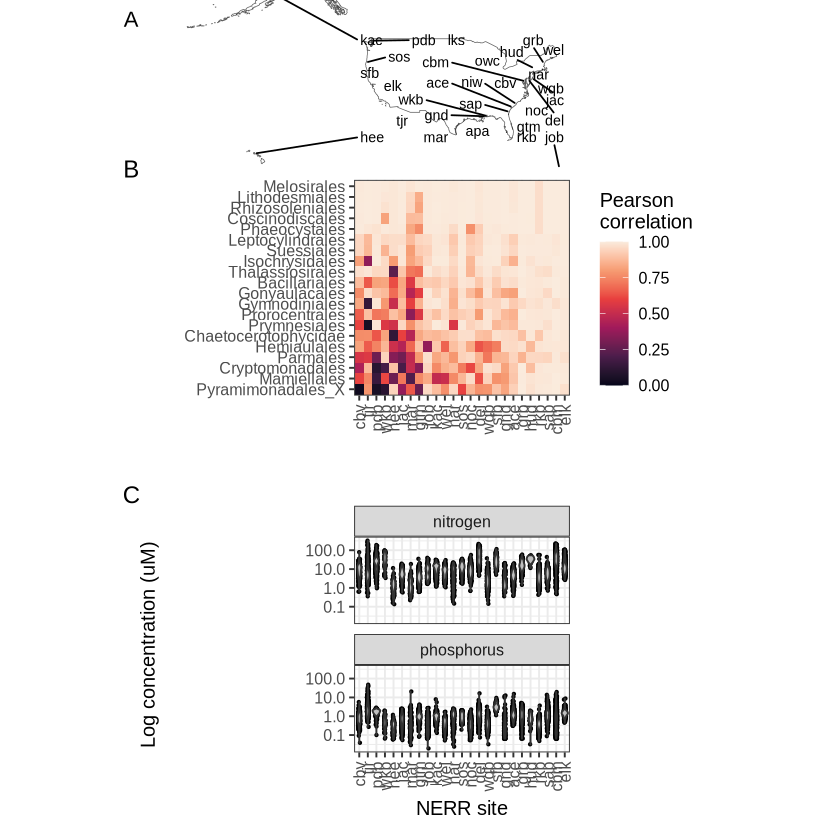

In [19]:
(map_plt/rotate_tile/nutrient_box)+plot_annotation(tag_levels = "A")
ggsave("../figures/figure_4_nutrients.pdf",width=10,height=12,units="in")

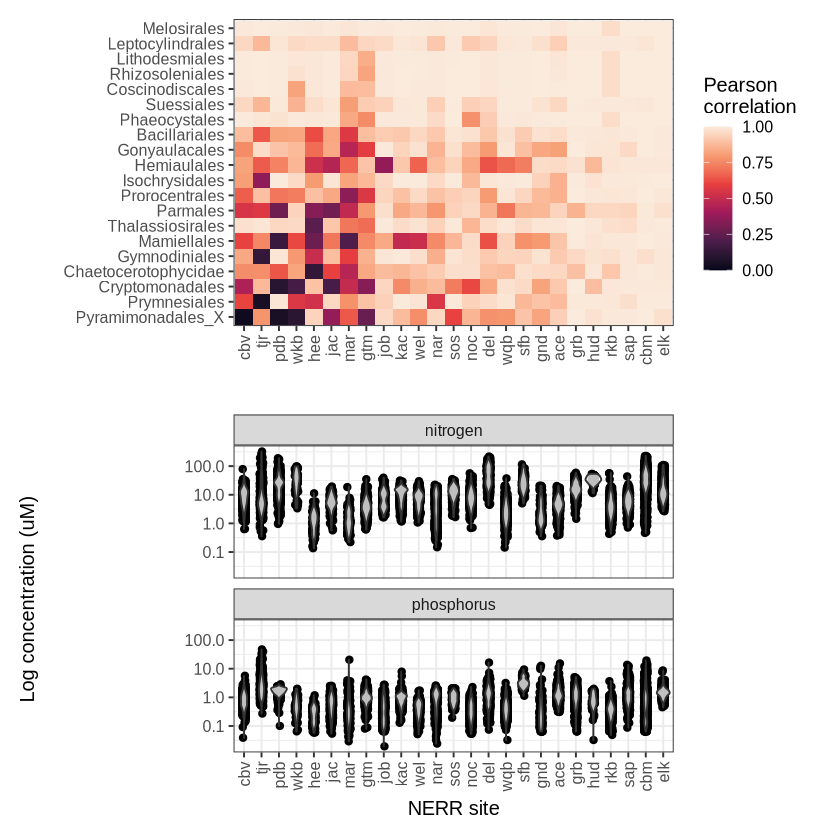

In [31]:
rotate_tile/nutrient_box

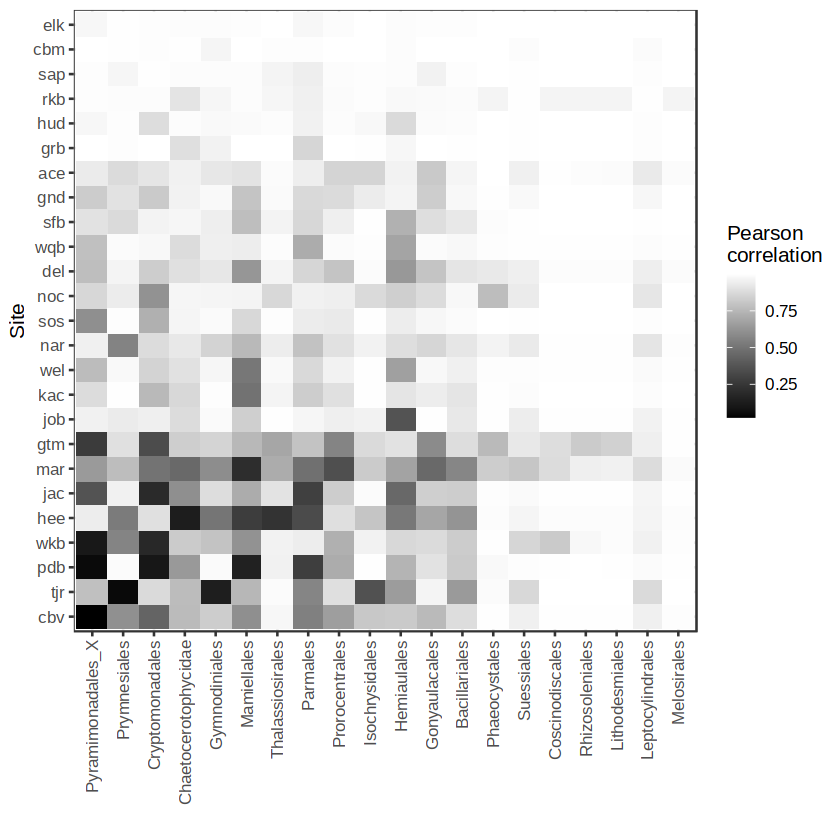

In [59]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)
ggplot(for_tile)+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_gradient(low="black",high="white",
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

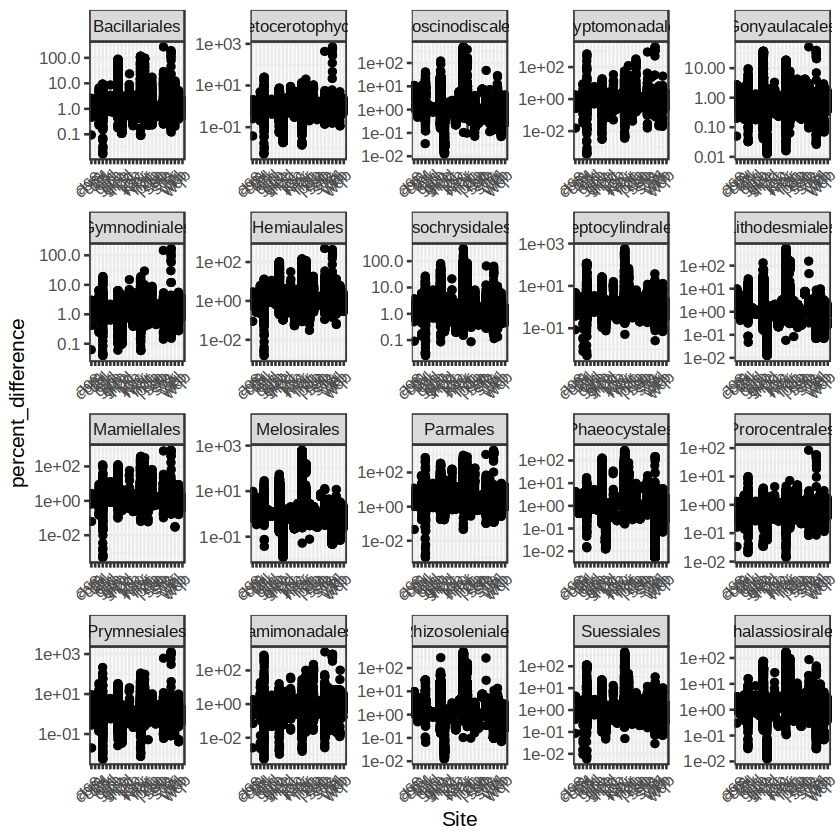

In [5]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=Site,y=percent_difference))+
    geom_jitter(aes(Site,y=percent_difference),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    facet_wrap(~taxon,scales="free") + 
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [1]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_jitter(aes(taxon,y=percent_difference,color=Site),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    facet_wrap(~Site) + 
    scale_y_log10() + 
    theme_bw(base_size=12)+ ylab("ratio allometry to metaT") + 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

ERROR: Error in ggplot(nerrs_merged %>% dplyr::mutate(percent_difference = allometry/metaT) %>% : could not find function "ggplot"


Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 58898 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 58898 rows containing missing values or values outside the scale range
(`geom_point()`).”


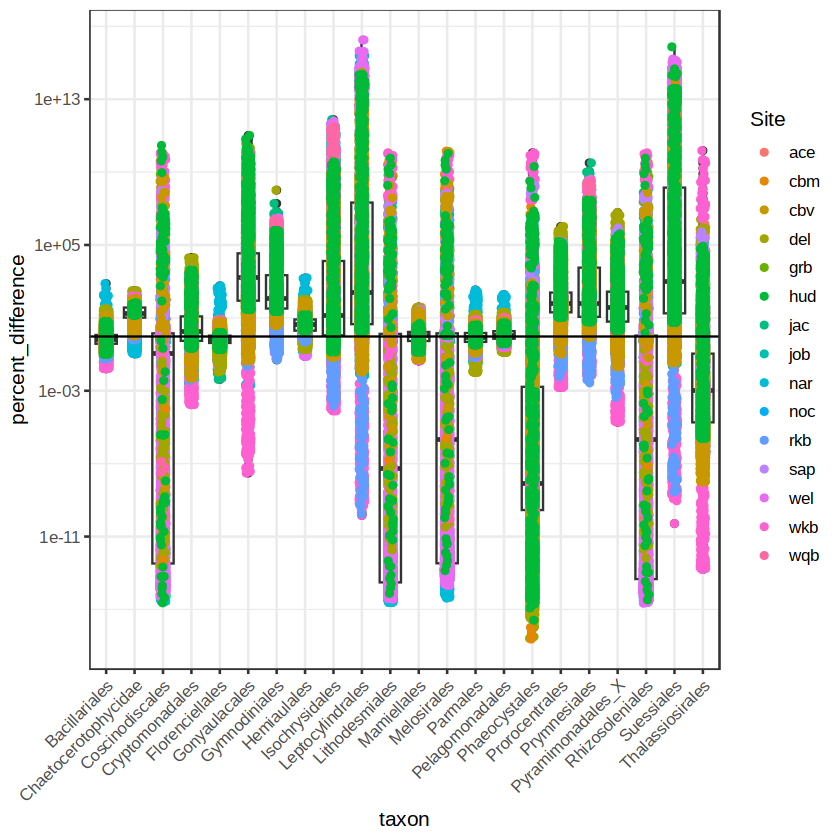

In [7]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_jitter(aes(taxon,y=percent_difference,color=Site),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

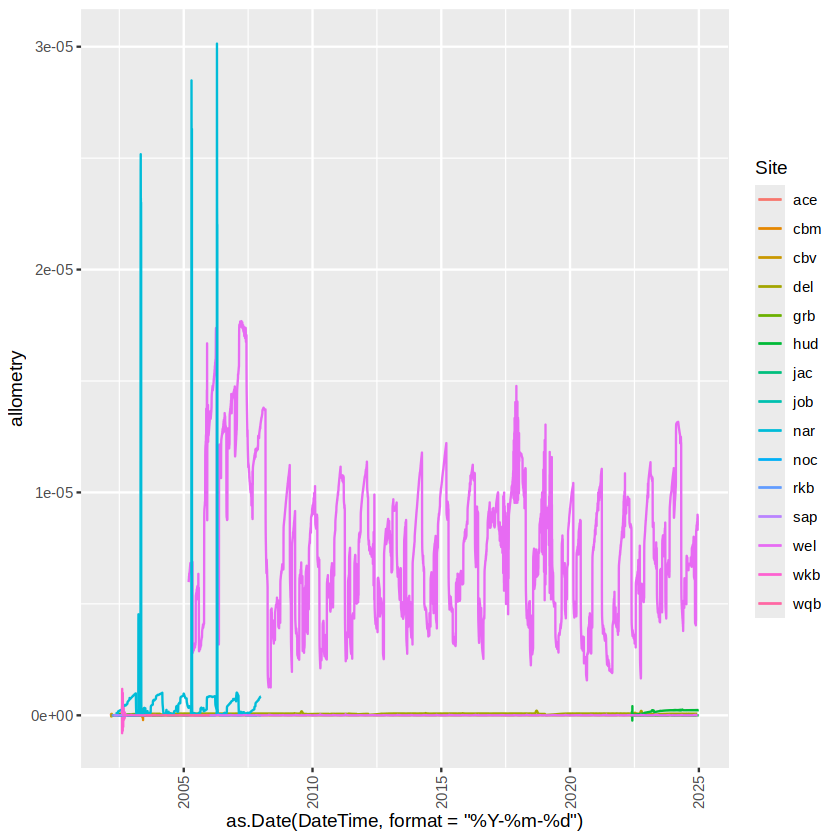

In [8]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Gonyaulacales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site))+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

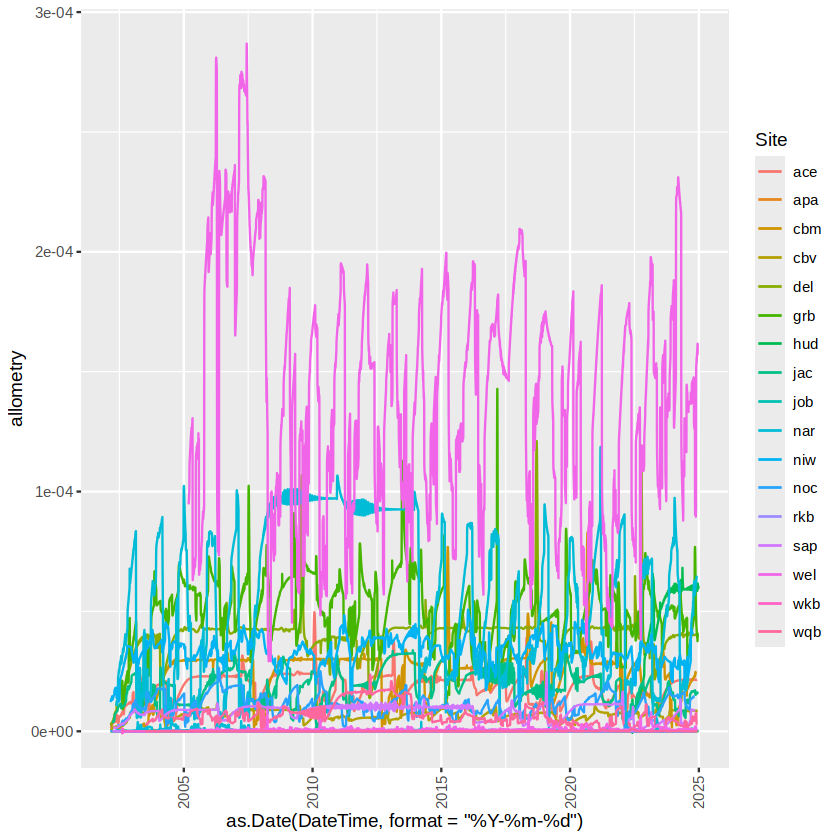

In [7]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Prorocentrales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site))+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

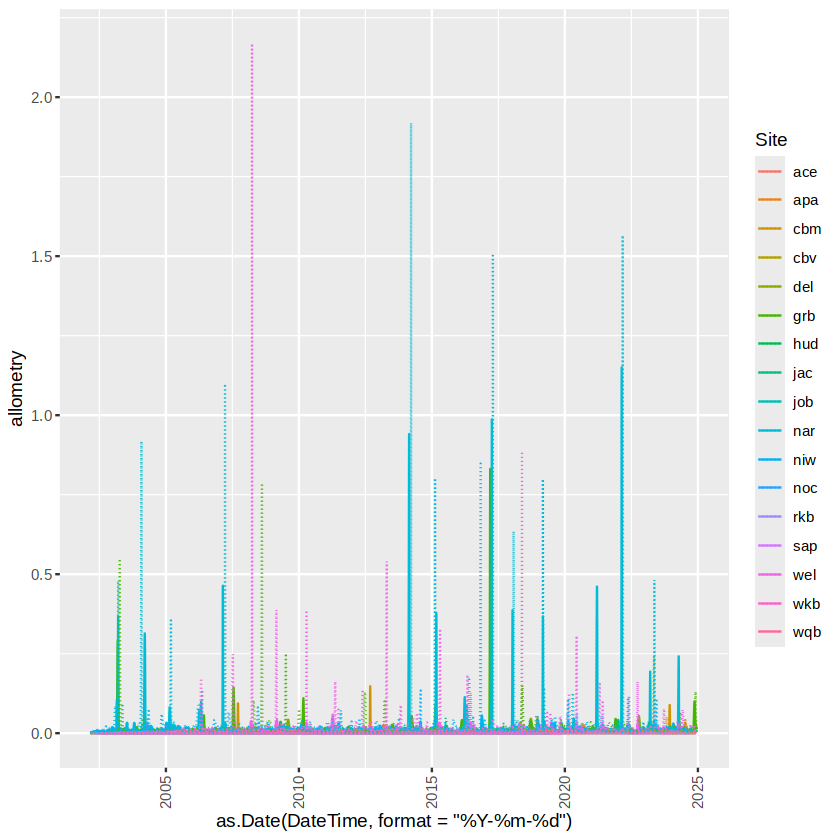

In [9]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Isochrysidales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site),linetype="dotted")+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

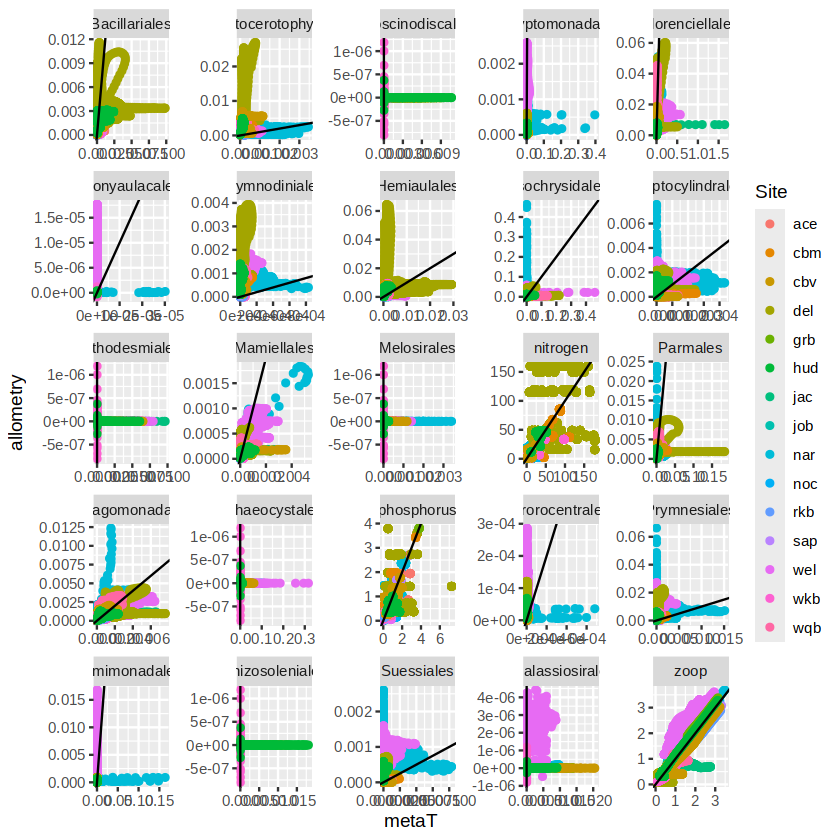

In [9]:
ggplot(nerrs_merged) + 
    geom_point(aes(x=metaT,y=allometry,color=Site))+
    geom_abline(aes(intercept=0,slope=1))+
    facet_wrap(~taxon,scales="free")

In [13]:
unique(nerrs_merged$Site)

[1] "ace" "wqb" "hud" "cbv" "wel" "noc" "cbm" "nar" "niw" "job" "jac" "rkb"
[13] "apa" "grb" "sap" "del" "wkb"